# Evaluate Re = 120, snapshot 5300

Loads the raw snapshot from the same case directory as evaluate_MLmodels.ipynb. Computes DNS h, q, tau_wall, shape_factor = integral(u**2*f dy), and u_interface = u(x,h). Coordinates and velocities are used as stored, matching the old notebook and training extractor. The three outputs are predicted directly, without adding a wall-shear baseline.

Use the Python (thinfilm-ml-py311) kernel. This is a held-out-snapshot evaluation only if this snapshot was excluded from training; Re=120 itself was among the configured training cases.


In [1]:
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


Device: cpu


## Configuration

The snapshot path is fixed to the requested case and label. Set the paths of your actual multi-output checkpoints below; use None to skip a model.


In [2]:
case_dir = Path('/blue/bala1s/krishnap.kalivel/TLFHydrodynamics/thinfilm-closure-ml/datasets/BasC/param_space/Re120_Ca0_010_theta45')
snapshot_label = 5300
snapshot_path = case_dir / 'output' / f'snapshot_{snapshot_label:06d}.h5'
checkpoint_paths = {
    'MLP': Path('saved_models/MLP_multioutput_k4_L4_N64.pt'),
    'CNN': Path('saved_models/1DCNN_multioutput_k4_L4_N64.pt'),
}
# Load only your own/trusted checkpoints: they contain NumPy metadata.
profile_time_index = 0
use_disturbed_region_mask = False
h_mean = 1.0
h_tolerance = 0.1
save_results = True
results_dir = Path('evaluation_Re120_t5300')
print('Raw snapshot:', snapshot_path)

Raw snapshot: /blue/bala1s/krishnap.kalivel/TLFHydrodynamics/thinfilm-closure-ml/datasets/BasC/param_space/Re120_Ca0_010_theta45/output/snapshot_005300.h5


In [3]:
def load_h5(filepath: str | Path, filename: str) -> dict[str, np.ndarray]:
    """
    Load all datasets from an HDF5 file.

    Parameters
    ----------
    filepath
        Directory containing the HDF5 file.

    filename
        Name of the HDF5 file, including the .h5 extension.

    Returns
    -------
    dict[str, np.ndarray]
        Dictionary containing all HDF5 datasets.

        The dictionary keys are the full dataset paths inside the
        HDF5 file. The values are NumPy arrays.

    Raises
    ------
    FileNotFoundError
        If the requested HDF5 file does not exist.

    OSError
        If the file exists but cannot be opened as an HDF5 file.
    """
    full_path = Path(filepath) / filename

    if not full_path.is_file():
        raise FileNotFoundError(
            f"HDF5 file was not found: {full_path.resolve()}"
        )

    data: dict[str, np.ndarray] = {}

    with h5py.File(full_path, mode="r") as h5_file:

        def load_dataset(name: str, obj: h5py.Dataset | h5py.Group) -> None:
            if isinstance(obj, h5py.Dataset):
                data[name] = obj[...]

        h5_file.visititems(load_dataset)

    return data

def compute_cell_centers(
    points: np.ndarray,
    topology: np.ndarray,
) -> np.ndarray:
    """
    Compute cell-center coordinates from mesh vertices and topology.

    Parameters
    ----------
    points
        Vertex coordinates with shape (n_points, n_dimensions).

    topology
        Cell connectivity with shape (n_cells, n_vertices_per_cell).
        Each row contains the vertex indices belonging to one cell.

    Returns
    -------
    np.ndarray
        Cell-center coordinates with shape (n_cells, n_dimensions).
    """
    points = np.asarray(points)
    topology = np.asarray(topology, dtype=np.int64)

    # Coordinates of every vertex belonging to every cell.
    # Shape:
    # (n_cells, n_vertices_per_cell, n_dimensions)
    cell_vertices = points[topology]

    # Average the vertex coordinates for each cell.
    cell_centers = cell_vertices.mean(axis=1)

    return cell_centers

def build_cartesian_cell_grid(
    cell_centers: np.ndarray,
    decimals: int = 12,
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """
    Build Cartesian cell-center coordinate matrices.

    Parameters
    ----------
    cell_centers
        Cell-center coordinates with shape (n_cells, 2) or
        (n_cells, 3).

    decimals
        Number of decimal places used when identifying unique
        coordinates. This prevents floating-point roundoff from
        creating duplicate coordinate values.

    Returns
    -------
    x_matrix
        Cell-center x coordinates with shape (ny, nx).

    y_matrix
        Cell-center y coordinates with shape (ny, nx).

    sorting_indices
        Indices that reorder cell-based fields into matrix order.
    """
    cell_centers = np.asarray(cell_centers)

    x = cell_centers[:, 0]
    y = cell_centers[:, 1]

    x_rounded = np.round(x, decimals=decimals)
    y_rounded = np.round(y, decimals=decimals)

    unique_x = np.unique(x_rounded)
    unique_y = np.unique(y_rounded)

    nx = len(unique_x)
    ny = len(unique_y)

    if nx * ny != len(cell_centers):
        raise ValueError(
            "The cell centers do not form a complete Cartesian grid. "
            f"Found nx={nx}, ny={ny}, but nx*ny={nx * ny} and "
            f"n_cells={len(cell_centers)}."
        )

    # Primary sorting key: y
    # Secondary sorting key: x
    sorting_indices = np.lexsort((x_rounded, y_rounded))

    x_sorted = x[sorting_indices]
    y_sorted = y[sorting_indices]

    x_matrix = x_sorted.reshape(ny, nx)
    y_matrix = y_sorted.reshape(ny, nx)

    return x_matrix, y_matrix, sorting_indices

def vector_to_matrices(
    vector: np.ndarray,
    sorting_indices: np.ndarray,
    matrix_shape: tuple[int, int],
) -> tuple[np.ndarray, ...]:
    """
    Convert a cell-based vector field into component matrices.

    Parameters
    ----------
    vector
        Vector field with shape (n_cells, n_components).

    sorting_indices
        Sorting indices returned by build_cartesian_cell_grid().

    matrix_shape
        Desired matrix shape, normally x_matrix.shape.

    Returns
    -------
    tuple[np.ndarray, ...]
        One matrix for each vector component.
    """
    vector = np.asarray(vector)

    if vector.ndim != 2:
        raise ValueError(
            f"Expected vector shape (n_cells, n_components), "
            f"but received {vector.shape}."
        )

    if vector.shape[0] != len(sorting_indices):
        raise ValueError(
            f"Vector contains {vector.shape[0]} cells, but the mesh contains "
            f"{len(sorting_indices)} cells."
        )

    vector_sorted = vector[sorting_indices]

    return tuple(
        vector_sorted[:, component].reshape(matrix_shape)
        for component in range(vector.shape[1])
    )

def scalar_to_matrix(
    scalar: np.ndarray,
    sorting_indices: np.ndarray,
    matrix_shape: tuple[int, int],
) -> np.ndarray:
    """
    Convert a cell-based scalar field into a 2D Cartesian matrix.

    Parameters
    ----------
    scalar
        Scalar field with one value per cell.

    sorting_indices
        Sorting indices returned by build_cartesian_cell_grid().

    matrix_shape
        Desired matrix shape, normally x_matrix.shape.

    Returns
    -------
    np.ndarray
        Scalar field with shape (ny, nx).
    """
    scalar = np.asarray(scalar).squeeze()

    if scalar.ndim != 1:
        raise ValueError(
            f"Expected a one-dimensional scalar field after squeezing, "
            f"but received shape {scalar.shape}."
        )

    if len(scalar) != len(sorting_indices):
        raise ValueError(
            f"Scalar contains {len(scalar)} values, but the mesh contains "
            f"{len(sorting_indices)} cells."
        )

    return scalar[sorting_indices].reshape(matrix_shape)

def depth_integral(
    x: np.ndarray,
    y: np.ndarray,
    field: np.ndarray,
    *,
    lower_boundary: float = 0.0,
) -> tuple[np.ndarray, np.ndarray]:
    """
    Depth-integrate a cell-centered field along y at every x-location.

    Computes

        I(x) = integral field(x, y) dy

    using a finite-volume sum:

        I(x_i) = sum_j field[j, i] * dy[j, i]

    Parameters
    ----------
    x
        Cell-center x-coordinate matrix with shape (ny, nx).

    y
        Cell-center y-coordinate matrix with shape (ny, nx).

    field
        Cell-centered field with shape (ny, nx).

    lower_boundary
        Physical location of the lower boundary. For a wall at y = 0,
        use the default value 0.0.

    Returns
    -------
    x_locations
        One-dimensional array of x locations with shape (nx,).

    integral
        Depth-integrated field at every x location with shape (nx,).
    """
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    field = np.asarray(field, dtype=float)

    if x.ndim != 2 or y.ndim != 2 or field.ndim != 2:
        raise ValueError("x, y, and field must be two-dimensional arrays.")

    if x.shape != y.shape or x.shape != field.shape:
        raise ValueError(
            "x, y, and field must have identical shapes. "
            f"Received x={x.shape}, y={y.shape}, "
            f"field={field.shape}."
        )

    ny, nx = field.shape

    if ny < 2:
        raise ValueError(
            "At least two cells in the y-direction are required "
            "to reconstruct cell boundaries."
        )

    x_locations = x[0, :].copy()
    integral = np.zeros(nx, dtype=float)

    for i in range(nx):
        y_column = y[:, i]
        field_column = field[:, i]

        # Ensure cells are ordered from bottom to top.
        order = np.argsort(y_column)
        y_sorted = y_column[order]
        field_sorted = field_column[order]

        if np.any(np.diff(y_sorted) <= 0.0):
            raise ValueError(
                f"Repeated or non-increasing y coordinates found at "
                f"x-index {i}."
            )

        # Reconstruct cell-face locations from cell centers.
        y_faces = np.empty(ny + 1, dtype=float)

        # Physical lower wall.
        y_faces[0] = lower_boundary

        # Interior faces lie halfway between neighboring cell centers.
        y_faces[1:ny] = 0.5 * (
            y_sorted[:-1] + y_sorted[1:]
        )

        # Extrapolate the upper face by half the final center spacing.
        y_faces[ny] = (
            y_sorted[-1]
            + 0.5 * (y_sorted[-1] - y_sorted[-2])
        )

        cell_heights = np.diff(y_faces)

        if np.any(cell_heights <= 0.0):
            raise ValueError(
                f"Non-positive cell height reconstructed at x-index {i}."
            )

        integral[i] = np.sum(
            field_sorted * cell_heights
        )

    return x_locations, integral

def compute_wall_shear(
    x: np.ndarray,
    y: np.ndarray,
    u: np.ndarray,
    mu: float = 1.0,
) -> tuple[np.ndarray, np.ndarray]:
    """
    Compute lower-wall shear stress from a cell-centered velocity field.

    Assumptions
    -----------
    - Uniform Cartesian mesh.
    - Lower wall is located at y = 0.
    - No-slip condition: u_wall = 0.
    - Cell centers are located at:
          y_j = (j + 1/2) * dy

    Parameters
    ----------
    x, y : ndarray, shape (ny, nx)
        Cell-center coordinates.

    u : ndarray, shape (ny, nx)
        Streamwise velocity.

    mu : float
        Dynamic viscosity.

    order : 4
        Accuracy order of the wall-gradient stencil.

    Returns
    -------
    x_wall : ndarray, shape (nx,)
        Streamwise coordinates along the wall.

    tau_w : ndarray, shape (nx,)
        Wall shear stress:
            tau_w = mu * (du/dy)_wall
    """

    if x.shape != y.shape or x.shape != u.shape:
        raise ValueError("x, y, and u must have identical shapes.")

    if u.ndim != 2:
        raise ValueError("x, y, and u must be two-dimensional arrays.")

    required_cells = {2: 2, 3: 3, 4: 4}

    order = 4
    if u.shape[0] < required_cells[order]:
        raise ValueError(
            f"Order {order} requires at least "
            f"{required_cells[order]} wall-normal cells."
        )

    dy = y[1, 0] - y[0, 0]

    if dy <= 0.0:
        raise ValueError(
            "The y coordinate must increase away from the lower wall."
        )

    u1 = u[0, :]
    u2 = u[1, :]
    u3 = u[2, :]
    u4 = u[3, :]

    dudy_wall = (
        3675.0 * u1
        - 1225.0 * u2
        + 441.0 * u3
        - 75.0 * u4
    ) / (840.0 * dy)

    tau_w = mu * dudy_wall

    return x[0, :], tau_w

flowfield_data = load_h5(snapshot_path.parent, snapshot_path.name)
required = {'Geometry/Points', 'Topology', 'Cells/f', 'Cells/u.x', 'Parameters/Re', 'Parameters/time'}
missing = required.difference(flowfield_data)
if missing:
    raise KeyError(f'Missing raw snapshot datasets: {sorted(missing)}')
Re_case = float(np.asarray(flowfield_data['Parameters/Re']).squeeze())
t_snapshot = float(np.asarray(flowfield_data['Parameters/time']).squeeze())
if not np.isclose(Re_case, 120.0):
    raise ValueError(f'Expected Re=120, got Re={Re_case}')
print(f'Loaded snapshot label {snapshot_label}; stored time={t_snapshot:g}; Re={Re_case:g}')
if not np.isclose(t_snapshot, snapshot_label):
    print('NOTE: snapshot filename label differs from stored time; plots use stored time.')

centers = compute_cell_centers(flowfield_data['Geometry/Points'], flowfield_data['Topology'])
x_grid, y_grid, order = build_cartesian_cell_grid(centers)
f = scalar_to_matrix(flowfield_data['Cells/f'], order, x_grid.shape)
velocity = np.asarray(flowfield_data['Cells/u.x'])
if velocity.ndim == 1:
    u = velocity[order].reshape(x_grid.shape)
else:
    u = vector_to_matrices(velocity, order, x_grid.shape)[0]

# The notebook's wall stencil assumes uniform centers at (j+1/2)*dy.
dy = y_grid[1, 0] - y_grid[0, 0]
expected_y = (np.arange(y_grid.shape[0]) + 0.5) * dy
if not np.allclose(y_grid, expected_y[:, None]):
    raise ValueError('Wall shear requires a uniform cell-centered mesh with a wall at y=0.')

x, h_snapshot = depth_integral(x_grid, y_grid, f)
_, q_snapshot = depth_integral(x_grid, y_grid, u*f)
_, shape_snapshot = depth_integral(x_grid, y_grid, u**2*f)
_, tau_snapshot = compute_wall_shear(x_grid, y_grid, u, mu=1.0)
ui_snapshot = np.array([
    np.interp(h_snapshot[i], y_grid[:, i], u[:, i])
    for i in range(len(x))
])
# Retain a singleton time dimension for the common prediction/plot routines.
h = h_snapshot[:, None]
q = q_snapshot[:, None]
t = np.array([t_snapshot])
target_names_dns = ['tau_wall', 'shape_factor', 'u_interface']
Y_dns = np.stack([tau_snapshot, shape_snapshot, ui_snapshot], axis=-1)[:, None, :]
print('DNS shapes:', h.shape, q.shape, Y_dns.shape)

Loaded snapshot label 5300; stored time=5300; Re=120
DNS shapes: (16384, 1) (16384, 1) (16384, 1, 3)


In [4]:
def make_evaluation_mask(h):
    if not use_disturbed_region_mask:
        return np.ones_like(h, dtype=bool)

    mask = np.zeros_like(h, dtype=bool)
    for it in range(h.shape[1]):
        disturbed = np.abs(h[:, it] - h_mean) > h_tolerance
        indices = np.flatnonzero(disturbed)
        if indices.size:
            mask[:indices[-1] + 1, it] = True
    return mask


evaluation_mask = make_evaluation_mask(h)
print(f"Retained by evaluation mask: {evaluation_mask.mean() * 100:.2f}%")


Retained by evaluation mask: 100.00%


## Model definitions and checkpoint loading


In [5]:
class WindowMLP(nn.Module):
    def __init__(self, input_dim, hidden_neurons, n_hidden_layers, output_dim):
        super().__init__()
        layers = []
        in_dim = input_dim
        for _ in range(n_hidden_layers):
            layers.extend([nn.Linear(in_dim, hidden_neurons), nn.Tanh()])
            in_dim = hidden_neurons
        layers.append(nn.Linear(in_dim, output_dim))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)


class LocalCNN1D(nn.Module):
    def __init__(self, input_channels, hidden_neurons, n_hidden_layers, output_dim):
        super().__init__()
        layers = []
        in_channels = input_channels
        for _ in range(n_hidden_layers):
            layers.extend([
                nn.Conv1d(in_channels, hidden_neurons, kernel_size=3, padding=1),
                nn.Tanh(),
            ])
            in_channels = hidden_neurons
        self.conv = nn.Sequential(*layers)
        self.head = nn.Sequential(
            nn.Linear(hidden_neurons, hidden_neurons),
            nn.Tanh(),
            nn.Linear(hidden_neurons, output_dim),
        )

    def forward(self, x):
        features = self.conv(x)
        return self.head(features[:, :, features.shape[-1] // 2])


def as_numpy(value):
    return value.detach().cpu().numpy() if torch.is_tensor(value) else np.asarray(value)


def load_model_bundle(label, path):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f"{label} checkpoint not found: {path}")

    # These checkpoints were produced locally and contain NumPy scaling arrays.
    checkpoint = torch.load(path, map_location=device, weights_only=False)
    checkpoint_targets = list(checkpoint.get("target_names", []))
    if checkpoint_targets != target_names_dns:
        raise ValueError(
            f"{label} targets are {checkpoint_targets}; expected {target_names_dns}. "
            "This may be an older single-output checkpoint."
        )

    k = int(checkpoint["k_space"])
    width = int(checkpoint["hidden_neurons"])
    depth = int(checkpoint["n_hidden_layers"])
    model_type = checkpoint["model_type"]

    if model_type == "WindowMLP":
        model = WindowMLP(1 + 2 * (2 * k + 1), width, depth, len(checkpoint_targets))
    elif model_type == "LocalCNN1D":
        model = LocalCNN1D(3, width, depth, len(checkpoint_targets))
    else:
        raise ValueError(f"Unsupported model_type in {label}: {model_type}")

    model.load_state_dict(checkpoint["model_state_dict"])
    model.to(device).eval()
    return {
        "label": label,
        "model": model,
        "model_type": model_type,
        "k": k,
        "X_mean": as_numpy(checkpoint["X_mean"]),
        "X_std": as_numpy(checkpoint["X_std"]),
        "Y_mean": as_numpy(checkpoint["Y_mean"]),
        "Y_std": as_numpy(checkpoint["Y_std"]),
        "checkpoint": checkpoint,
    }


bundles = {}
for label, path in checkpoint_paths.items():
    if path is not None:
        bundles[label] = load_model_bundle(label, path)
        b = bundles[label]
        print(f"{label}: {b['model_type']}, k={b['k']}, epoch={b['checkpoint']['epoch']}")

if not bundles:
    raise ValueError("Set at least one checkpoint path.")


MLP: WindowMLP, k=4, epoch=100
CNN: LocalCNN1D, k=4, epoch=97


## Reconstruct inputs and predict

Boundary locations without a complete \(2k+1\) window are intentionally left as `NaN`.


In [6]:
def build_inputs(bundle):
    k = bundle["k"]
    window_size = 2 * k + 1
    nx, nt = h.shape
    X_list, ix_list, it_list = [], [], []

    for it in range(nt):
        for ix in range(k, nx - k):
            if not evaluation_mask[ix, it]:
                continue
            sl = slice(ix - k, ix + k + 1)
            h_window, q_window = h[sl, it], q[sl, it]
            if bundle["model_type"] == "WindowMLP":
                sample = np.concatenate(([Re_case], h_window, q_window))
            else:
                sample = np.stack([
                    h_window,
                    q_window,
                    np.full(window_size, Re_case),
                ])
            target = Y_dns[ix, it, :]
            if np.all(np.isfinite(sample)) and np.all(np.isfinite(target)):
                X_list.append(sample)
                ix_list.append(ix)
                it_list.append(it)
    return (
        np.asarray(X_list, dtype=np.float32),
        np.asarray(ix_list, dtype=int),
        np.asarray(it_list, dtype=int),
    )


def evaluate_bundle(bundle, inference_batch_size=65536):
    X, ix, it = build_inputs(bundle)
    if len(X) == 0:
        raise ValueError(f"No valid samples for {bundle['label']}.")
    X_scaled = ((X - bundle["X_mean"]) / bundle["X_std"]).astype(np.float32)
    pieces = []
    with torch.no_grad():
        for start in range(0, len(X_scaled), inference_batch_size):
            xb = torch.from_numpy(X_scaled[start:start + inference_batch_size]).to(device)
            pieces.append(bundle["model"](xb).cpu().numpy())
    pred_scaled = np.concatenate(pieces)
    pred = pred_scaled * bundle["Y_std"] + bundle["Y_mean"]
    truth = Y_dns[ix, it, :]
    full = np.full(Y_dns.shape, np.nan)
    full[ix, it, :] = pred
    return {"prediction": pred, "truth": truth, "full": full, "ix": ix, "it": it}


results = {label: evaluate_bundle(bundle) for label, bundle in bundles.items()}
for label, result in results.items():
    print(label, "evaluated samples:", len(result["truth"]))


MLP evaluated samples: 16376
CNN evaluated samples: 16376


## Metrics for Re=120, snapshot 5300


In [7]:
metric_rows = []
for model_label, result in results.items():
    for j, target in enumerate(target_names_dns):
        truth, pred = result["truth"][:, j], result["prediction"][:, j]
        rmse = np.sqrt(mean_squared_error(truth, pred))
        value_range = truth.max() - truth.min()
        metric_rows.append({
            "model": model_label,
            "target": target,
            "MAE": mean_absolute_error(truth, pred),
            "RMSE": rmse,
            "R2": r2_score(truth, pred),
            "NRMSE_std": rmse / np.std(truth) if np.std(truth) > 0 else np.nan,
            "NRMSE_range": rmse / value_range if value_range > 0 else np.nan,
            "bias": np.mean(pred - truth),
        })

metrics = pd.DataFrame(metric_rows).set_index(["model", "target"])
display(metrics)


MAE      RMSE        R2  NRMSE_std  NRMSE_range  \
model target                                                               
MLP   tau_wall      0.143710  0.256147  0.971615   0.168479     0.010102   
      shape_factor  0.058931  0.072858  0.996282   0.060979     0.010979   
      u_interface   0.028602  0.080902  0.966470   0.183112     0.024056   
CNN   tau_wall      0.107074  0.183810  0.985383   0.120900     0.007249   
      shape_factor  0.028269  0.050916  0.998184   0.042614     0.007673   
      u_interface   0.025684  0.075258  0.970985   0.170339     0.022378   

                        bias  
model target                  
MLP   tau_wall      0.029067  
      shape_factor -0.053468  
      u_interface   0.003165  
CNN   tau_wall      0.033043  
      shape_factor -0.014889  
      u_interface  -0.002253

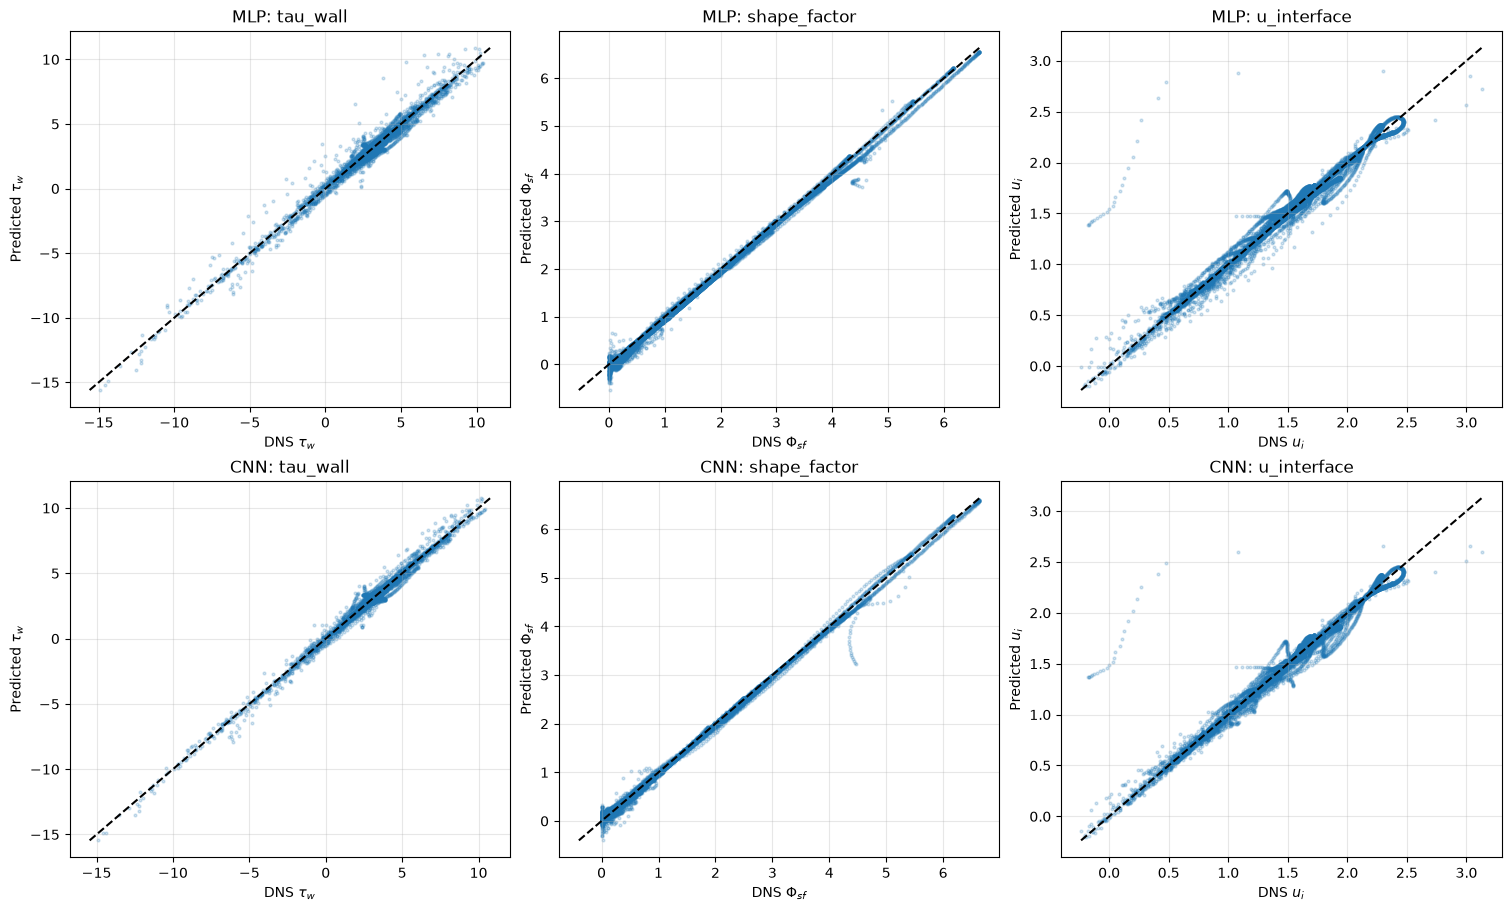

In [8]:
target_labels = [r"$\tau_w$", r"$\Phi_{sf}$", r"$u_i$"]
fig, axes = plt.subplots(len(results), 3, figsize=(15, 4.5 * len(results)), squeeze=False, constrained_layout=True)
rng = np.random.default_rng(42)

for row, (model_label, result) in enumerate(results.items()):
    n = len(result["truth"])
    sample = rng.choice(n, min(n, 30000), replace=False)
    for j, target in enumerate(target_names_dns):
        truth = result["truth"][sample, j]
        pred = result["prediction"][sample, j]
        lo, hi = min(truth.min(), pred.min()), max(truth.max(), pred.max())
        ax = axes[row, j]
        ax.scatter(truth, pred, s=4, alpha=0.2)
        ax.plot([lo, hi], [lo, hi], "--", color="black")
        ax.set_title(f"{model_label}: {target}")
        ax.set_xlabel(f"DNS {target_labels[j]}")
        ax.set_ylabel(f"Predicted {target_labels[j]}")
        ax.grid(True, alpha=0.3)
plt.show()


## Spatial profiles at snapshot 5300


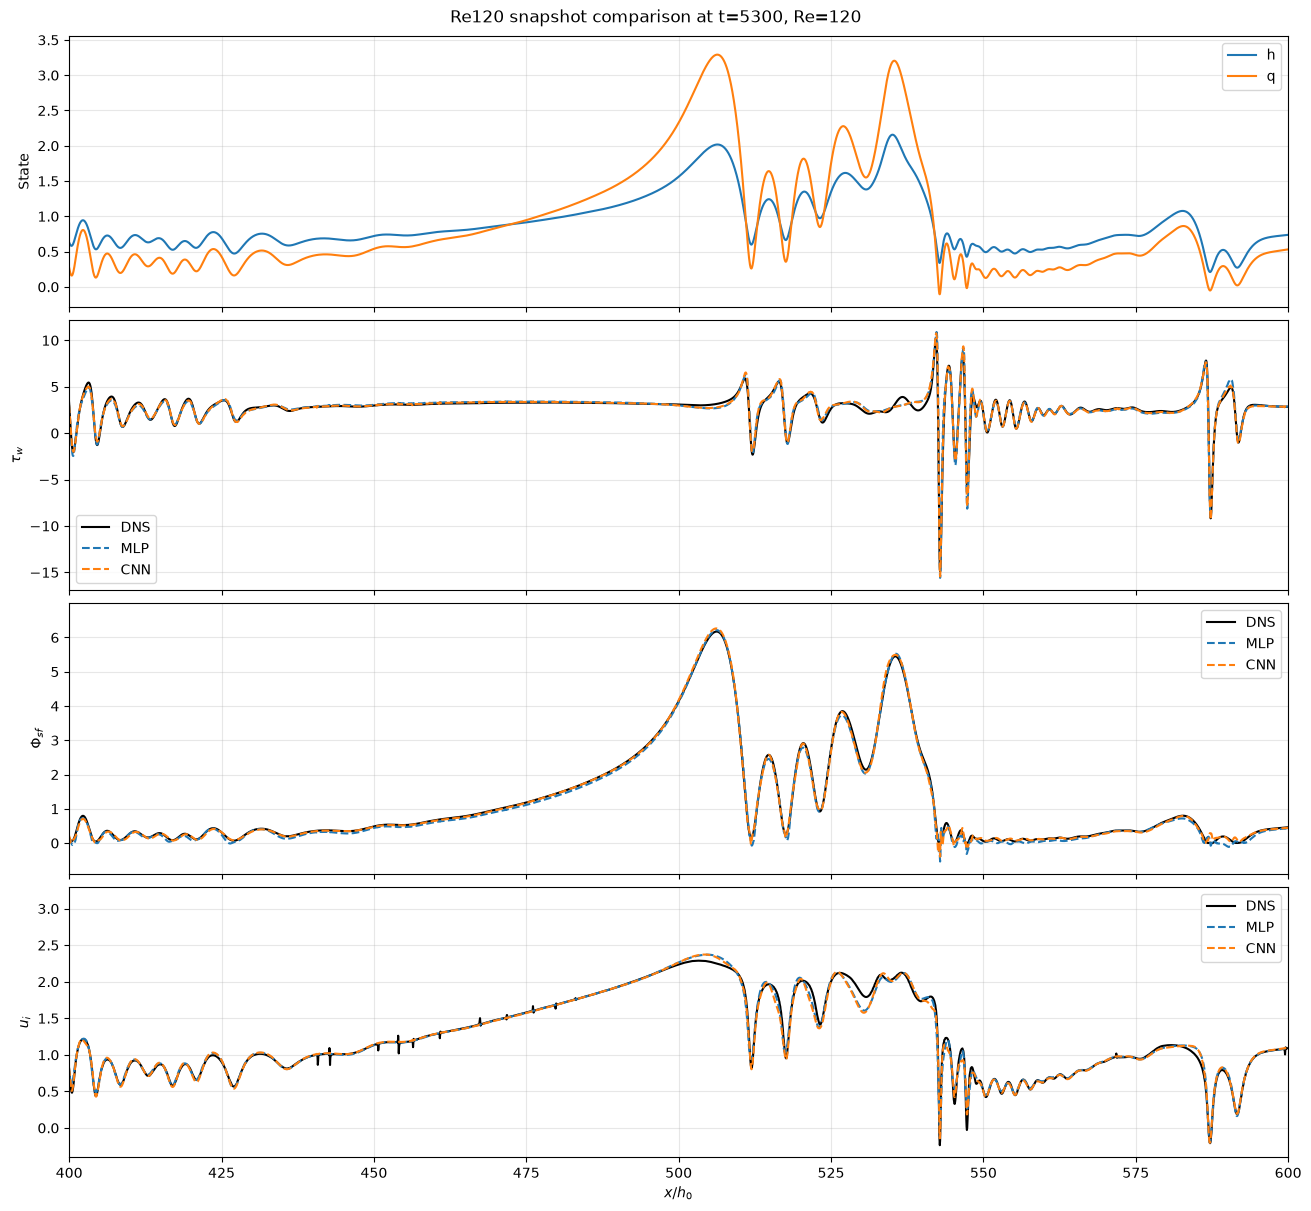

In [9]:
xlim1 = 400
xlim2 = 600

it_plot = profile_time_index % len(t)
fig, axes = plt.subplots(
    4, 1, figsize=(13, 12), sharex=True, constrained_layout=True
)

axes[0].plot(x, h[:, it_plot], label="h")
axes[0].plot(x, q[:, it_plot], label="q")
axes[0].set_ylabel("State")
axes[0].legend()

for j, (target, target_label) in enumerate(
    zip(target_names_dns, target_labels), start=1
):
    axes[j].plot(
        x, Y_dns[:, it_plot, j - 1],
        color="black", linewidth=1.5, label="DNS"
    )
    for model_label, result in results.items():
        axes[j].plot(
            x, result["full"][:, it_plot, j - 1],
            "--", label=model_label
        )
    axes[j].set_ylabel(target_label)
    axes[j].legend()

for ax in axes:
    ax.set_xlim(xlim1, xlim2)
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel(r"$x/h_0$")
fig.suptitle(
    f"Re120 snapshot comparison at t={t[it_plot]:.6g}, Re={Re_case:g}"
)
plt.show()

## Error as a function of streamwise position

This helps reveal whether aggregate performance is hiding localized failures near steep waves or boundaries.


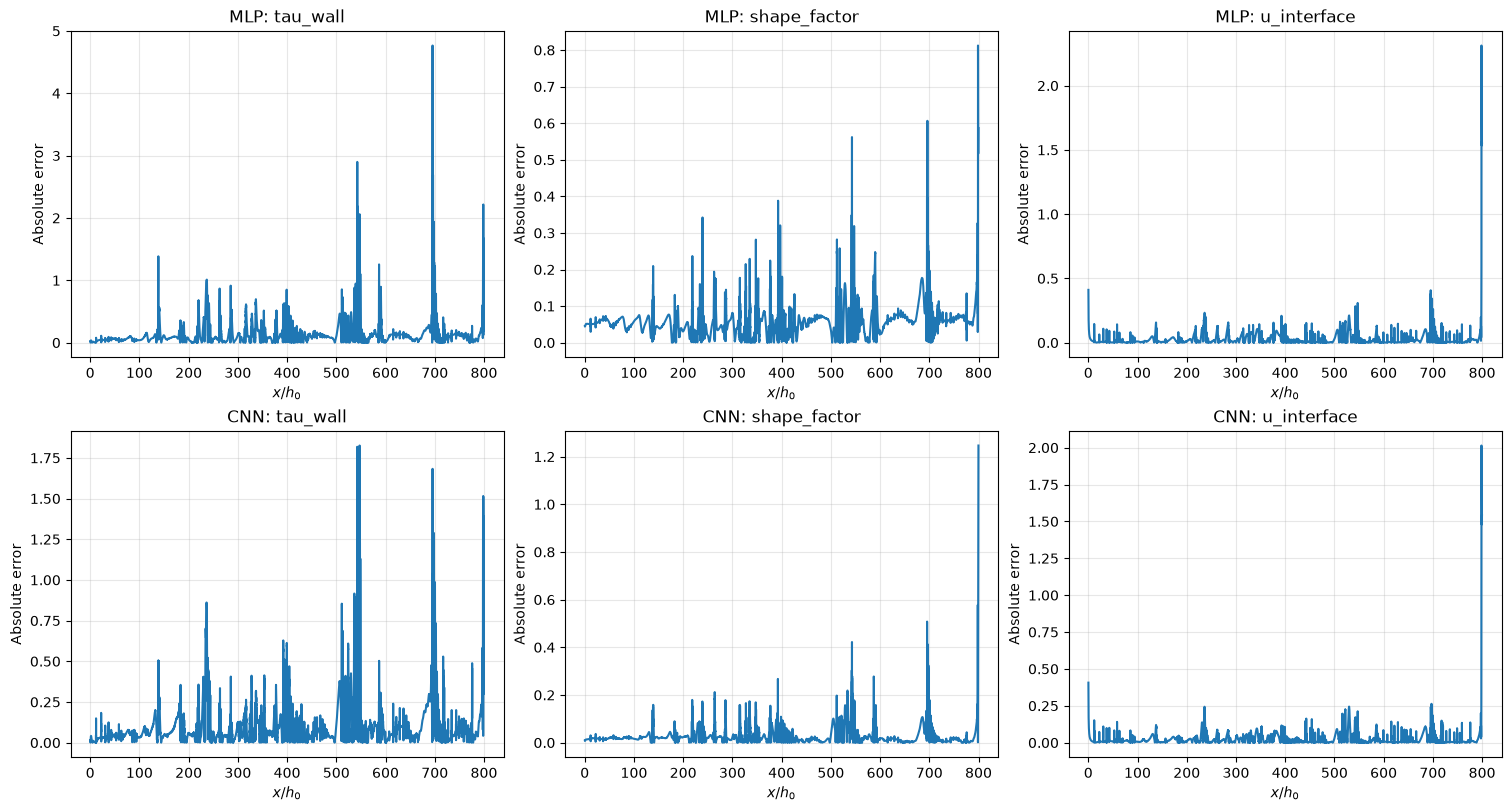

In [10]:
fig, axes = plt.subplots(len(results), 3, figsize=(15, 4 * len(results)), squeeze=False, constrained_layout=True)
for row, (model_label, result) in enumerate(results.items()):
    for j, target in enumerate(target_names_dns):
        abs_error = np.abs(result["full"][:, :, j] - Y_dns[:, :, j])
        valid_count = np.sum(np.isfinite(abs_error), axis=1)
        mean_abs_error_x = np.divide(
            np.nansum(abs_error, axis=1), valid_count,
            out=np.full(len(x), np.nan), where=valid_count > 0,
        )
        axes[row, j].plot(x, mean_abs_error_x)
        axes[row, j].set_title(f"{model_label}: {target}")
        axes[row, j].set_xlabel(r"$x/h_0$")
        axes[row, j].set_ylabel("Absolute error")
        axes[row, j].grid(True, alpha=0.3)
plt.show()


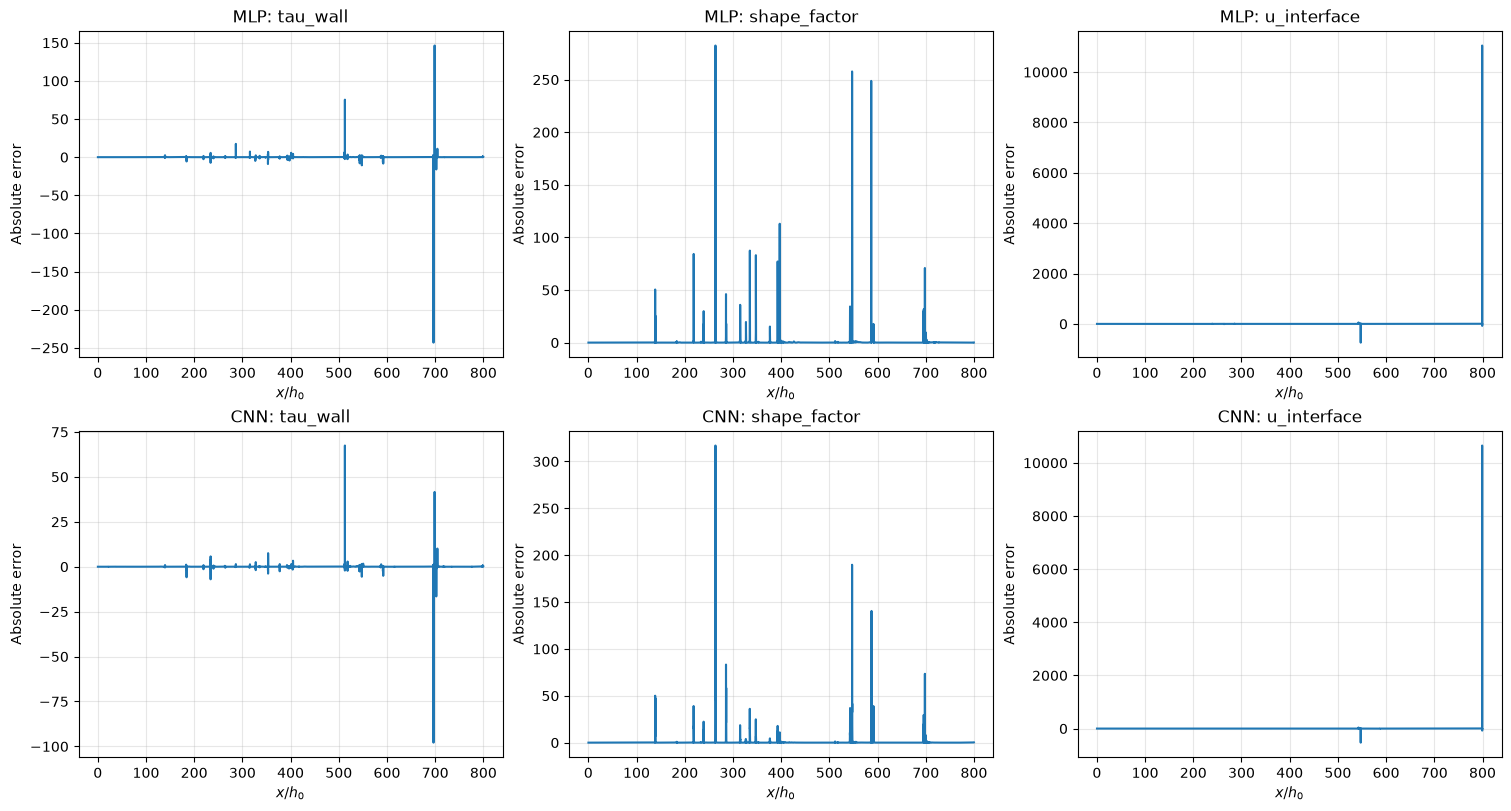

In [11]:
fig, axes = plt.subplots(len(results), 3, figsize=(15, 4 * len(results)), squeeze=False, constrained_layout=True)
for row, (model_label, result) in enumerate(results.items()):
    for j, target in enumerate(target_names_dns):
        rel_error = np.abs(result["full"][:, :, j] - Y_dns[:, :, j]) / Y_dns[:, :, j]
        valid_count = np.sum(np.isfinite(rel_error), axis=1)
        mean_rel_error_x = np.divide(
            np.nansum(rel_error, axis=1), valid_count,
            out=np.full(len(x), np.nan), where=valid_count > 0,
        )
        axes[row, j].plot(x, mean_rel_error_x)
        axes[row, j].set_title(f"{model_label}: {target}")
        axes[row, j].set_xlabel(r"$x/h_0$")
        axes[row, j].set_ylabel("Absolute error")
        axes[row, j].grid(True, alpha=0.3)
plt.show()


## Shape factor in the context of Lavalle's model

Let's define the shape factor as $\int_0^h u^2 dy = \Phi_{sf} \dfrac{q^2}{h}$. The ML operator predicts the entire RHS. 
For a two-equation model, the shape factor features in the flux term of the momentum-equation, i.e. $\partial_x \left(\Phi_{sf} \dfrac{q^2}{h} \right)$ 

The two-equation model of Lavelle et al. does a couple of things with the shape factor.

First, it only considers the leading order contribution, i.e. $\Phi_{sf} = \dfrac{6}{5}$. 

Secondly, it decomposes $\int_0^h u^2 dy = \dfrac{6}{5} \dfrac{q^2}{h} = \dfrac{q^2}{h} + \dfrac{1}{45} \Lambda^2 h^5$ to maintain Galilean invariance. It does so by expressing the leading order local flow rate in terms of the interface height. 

To develop the ML-augmented solver, we are retaining the flux term of Lavalle. The modified shape factor can be included in two ways.
1. Add the $\left(\Phi_{sf} - 1 \right) \dfrac{q^2}{h}$ as a function of $h$ and $Re$ alone and include it in the $P(h)$ term. 
2. Keep the existing flux term of Lavalle et al. and move the $\left(\Phi_{sf} - 1 \right) \dfrac{q^2}{h}$. This will result in an additional $- \partial_x \left( (\Phi_{sf,ml} - 1) \dfrac{q^2}{h}  - \dfrac{\Lambda^2}{45} h^5 \right)$ on the RHS. 


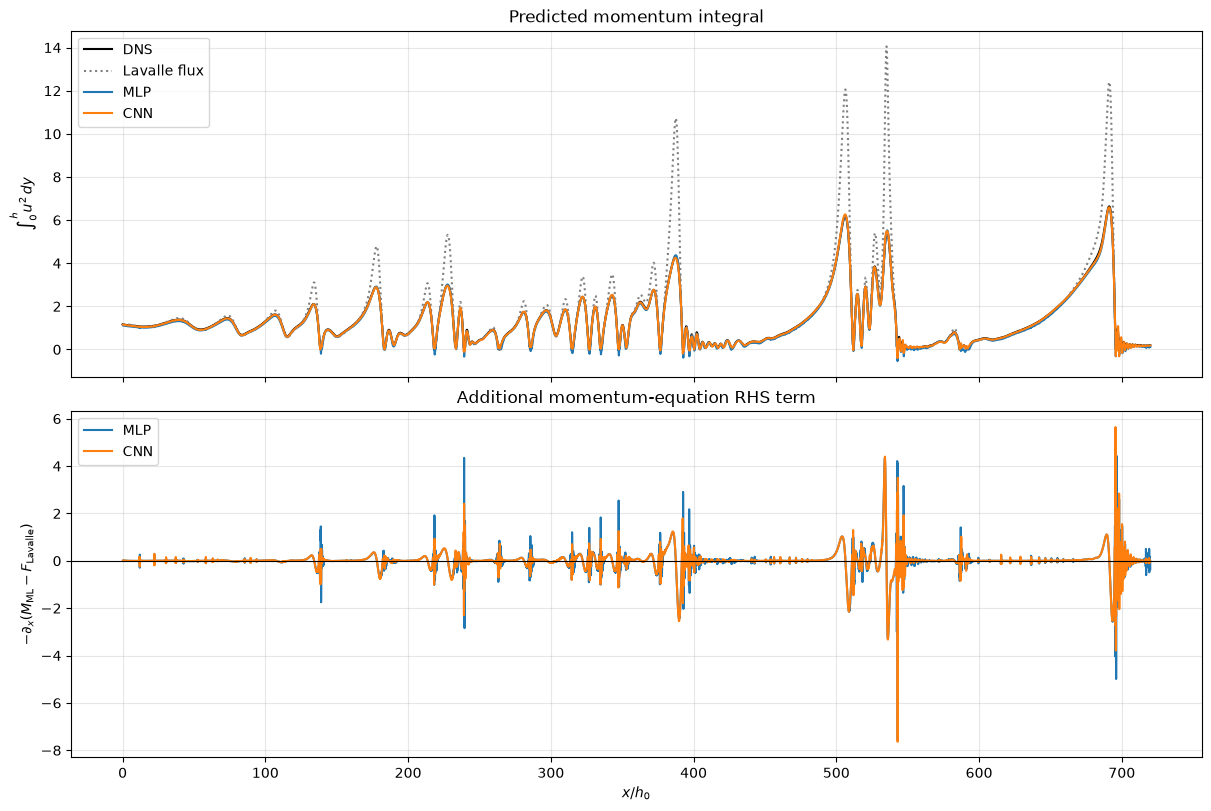

In [12]:
Lambda = 3.0

h_profile = h[:, 0]
q_profile = q[:, 0]
M_dns = Y_dns[:, 0, 1]

# Retain the first 90% of the physical x-domain.
x_cutoff = x.min() + 0.9 * (x.max() - x.min())
domain_mask = x <= x_cutoff

F_lavalle = q_profile**2 / h_profile + (Lambda**2 / 45.0) * h_profile**5

shape_flux_corrections = {}

fig, axes = plt.subplots(
    2, 1, figsize=(12, 8), sharex=True, constrained_layout=True
)

axes[0].plot(x[domain_mask], M_dns[domain_mask],
             color="black", linewidth=1.5, label="DNS")
axes[0].plot(x[domain_mask], F_lavalle[domain_mask],
             color="gray", linestyle=":", label="Lavalle flux")

for model_name, result in results.items():
    M_ml = result["full"][:, 0, 1]  # Predicted integral of u² f dy
    delta_flux = M_ml - F_lavalle

    valid = np.flatnonzero(domain_mask & np.isfinite(delta_flux))
    if len(valid) < 3 or np.any(np.diff(valid) != 1):
        raise ValueError(
            f"{model_name}: fewer than three contiguous valid x points."
        )

    rhs_correction = np.full_like(delta_flux, np.nan)
    rhs_correction[valid] = -np.gradient(
        delta_flux[valid], x[valid], edge_order=2
    )

    shape_flux_corrections[model_name] = {
        "predicted_integral": M_ml,
        "delta_flux": delta_flux,
        "rhs_correction": rhs_correction,
    }

    axes[0].plot(x[valid], M_ml[valid], label=model_name)
    axes[1].plot(x[valid], rhs_correction[valid], label=model_name)

axes[0].set_ylabel(r"$\int_0^h u^2\,dy$")
axes[0].set_title("Predicted momentum integral")

axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_ylabel(r"$-\partial_x(M_{\rm ML}-F_{\rm Lavalle})$")
axes[1].set_xlabel(r"$x/h_0$")
axes[1].set_title("Additional momentum-equation RHS term")

for ax in axes:
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.show()

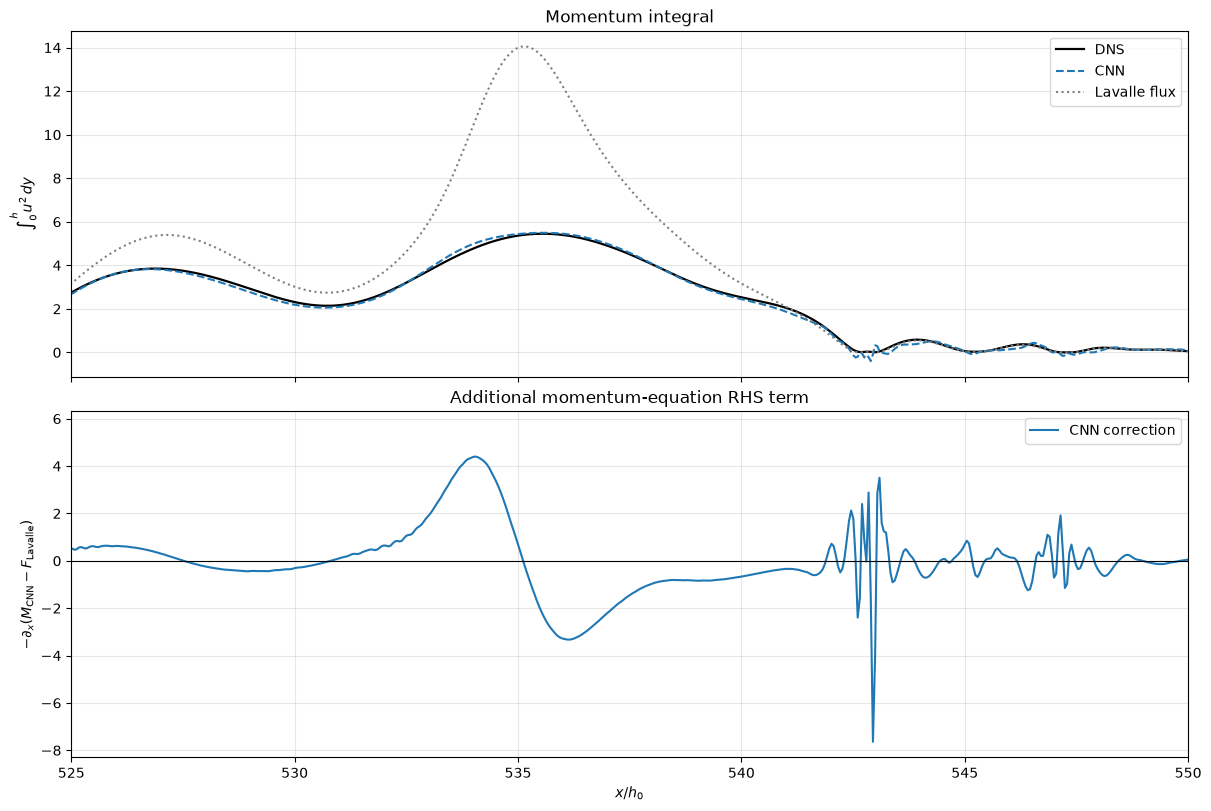

In [13]:
xlim1 = 525
xlim2 = 550

cnn = shape_flux_corrections["CNN"]

plot_mask = (
    (x <= x.min() + 0.9 * (x.max() - x.min()))
    & np.isfinite(cnn["rhs_correction"])
)

fig, axes = plt.subplots(
    2, 1, figsize=(12, 8), sharex=True, constrained_layout=True
)

axes[0].plot(
    x[plot_mask], Y_dns[plot_mask, 0, 1],
    color="black", linewidth=1.6, label="DNS"
)
axes[0].plot(
    x[plot_mask], cnn["predicted_integral"][plot_mask],
    color="tab:blue", linestyle="--", label="CNN"
)
axes[0].plot(
    x[plot_mask], F_lavalle[plot_mask],
    color="gray", linestyle=":", label="Lavalle flux"
)
axes[0].set_ylabel(r"$\int_0^h u^2\,dy$")
axes[0].set_title("Momentum integral")
axes[0].legend()

axes[1].plot(
    x[plot_mask], cnn["rhs_correction"][plot_mask],
    color="tab:blue", label="CNN correction"
)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_ylabel(r"$-\partial_x(M_{\rm CNN}-F_{\rm Lavalle})$")
axes[1].set_xlabel(r"$x/h_0$")
axes[1].set_xlim(xlim1, xlim2)
axes[1].set_title("Additional momentum-equation RHS term")
axes[1].legend()

for ax in axes:
    ax.grid(True, alpha=0.3)

plt.show()

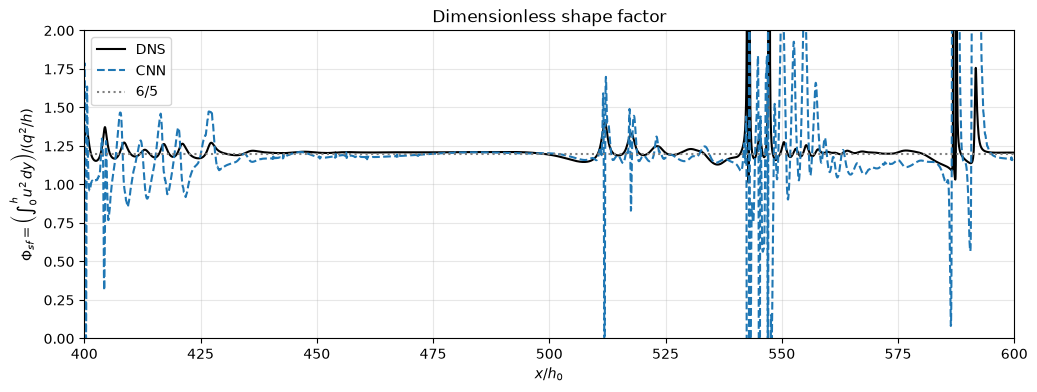

In [14]:
xlim1 = 400
xlim2 = 600
M_dns = Y_dns[:, 0, 1]
M_cnn = shape_flux_corrections["CNN"]["predicted_integral"]

denominator = q[:, 0]**2 / h[:, 0]
tol = 1e-10 * np.nanmax(np.abs(denominator))

plot_mask = (
    (x <= x.min() + 0.9 * (x.max() - x.min()))
    & np.isfinite(M_dns)
    & np.isfinite(M_cnn)
    & np.isfinite(denominator)
    & (np.abs(denominator) > tol)
)

phi_dns = M_dns[plot_mask] / denominator[plot_mask]
phi_cnn = M_cnn[plot_mask] / denominator[plot_mask]

plt.figure(figsize=(12, 4))
plt.plot(x[plot_mask], phi_dns, color="black", label="DNS")
plt.plot(x[plot_mask], phi_cnn, "--", color="tab:blue", label="CNN")
plt.axhline(6 / 5, color="gray", linestyle=":", label=r"$6/5$")
plt.xlabel(r"$x/h_0$")
plt.ylabel(r"$\Phi_{sf} = \left(\int_0^h u^2\,dy\right)/(q^2/h)$")
plt.title("Dimensionless shape factor")
plt.grid(True, alpha=0.3)
plt.ylim(0, 2)
plt.xlim(xlim1, xlim2)
plt.legend()
plt.show()

## Wall friction in the context of Lavalle's model

The wall friction factor is defined as $\tau_w = \partial_y u |_{y = 0}$. 

The analytical formulation for Lavalle's $\tau_w$ before any manipulations is 
\begin{equation}
    \tau_{w,Lavalle} = \dfrac{3q}{h^2} - \dfrac{1}{15} Re \Lambda^2 h^4 \partial_x h
\end{equation}

The second term on the RHS is rewritten as $\dfrac{1}{15} Re \Lambda^2 h^4 \partial_x h = \partial_x \left( \dfrac{1}{75} Re \Lambda^2 h^5 \right)$ and moved to the flux term on the LHS. 

Similarly, if our thin film solver is to utilize Lavalle's framework, the quantity to be evaluated on the RHS will be $\tau_{w,ML} - \tau_{w,Lavalle}$

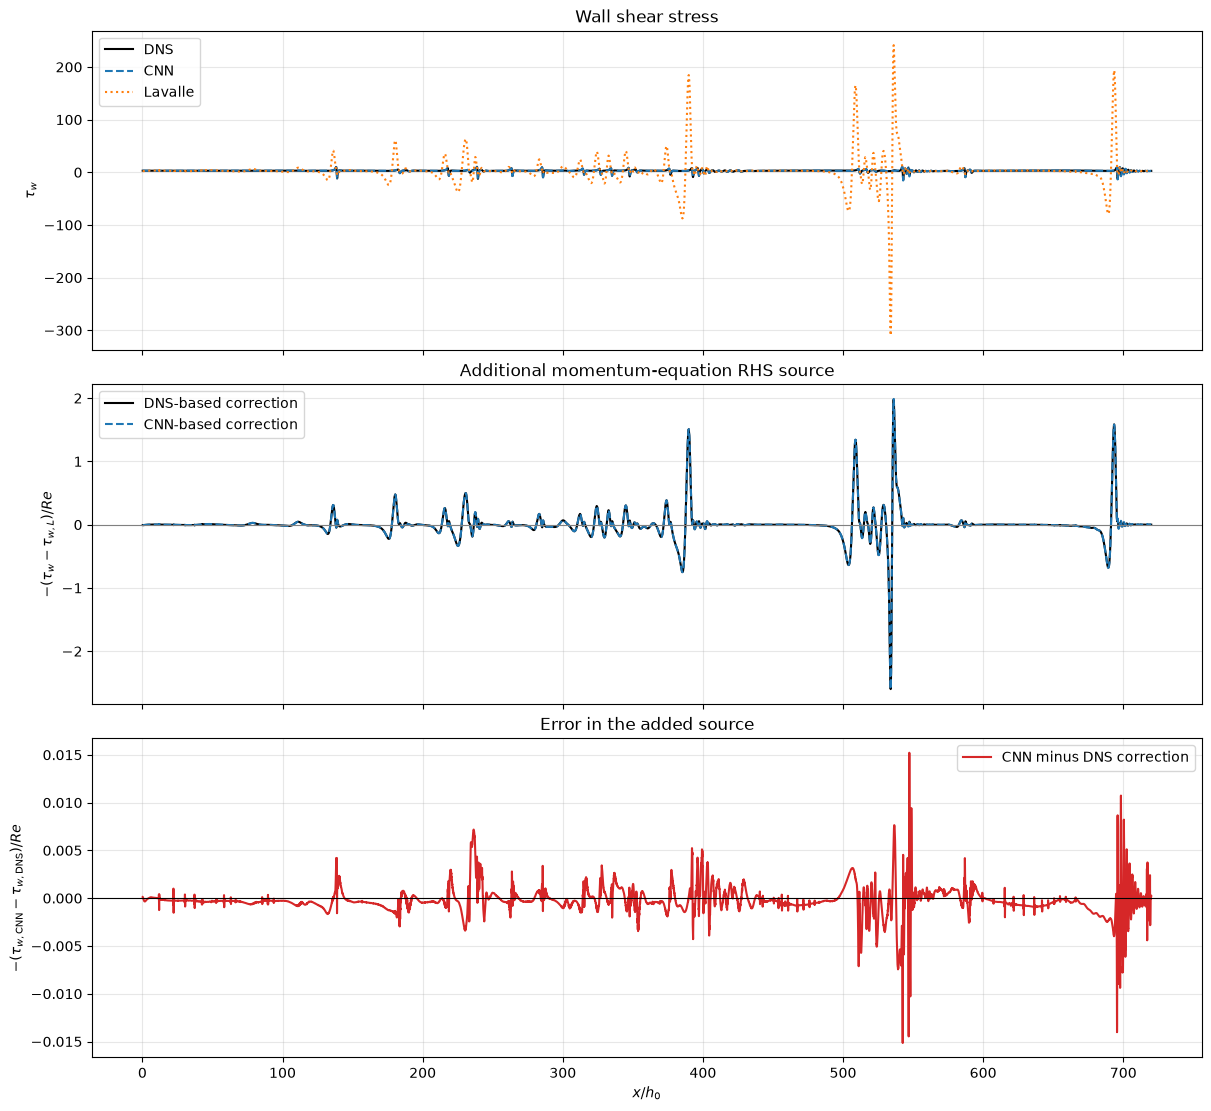

RHS correction error: MAE = 0.000903685, RMSE = 0.00152149


In [15]:
Lambda = 3.0

h_profile = h[:, 0]
q_profile = q[:, 0]
tau_dns = Y_dns[:, 0, 0]
tau_cnn = results["CNN"]["full"][:, 0, 0]

# Use the same h_x discretization here as in the numerical solver
# for a closer comparison with its retained Lavalle term.
h_x = np.gradient(h_profile, x, edge_order=2)

tau_lavalle = (
    3.0 * q_profile / h_profile**2
    - (Re_case * Lambda**2 / 15.0) * h_profile**4 * h_x
)

delta_tau_dns = tau_dns - tau_lavalle
delta_tau_cnn = tau_cnn - tau_lavalle

# Actual additional RHS source in Lavalle's momentum equation.
source_dns = -delta_tau_dns / Re_case
source_cnn = -delta_tau_cnn / Re_case
source_error = source_cnn - source_dns  # = -(tau_cnn - tau_dns) / Re_case

x_cutoff = x.min() + 0.9 * (x.max() - x.min())
plot_mask = (
    (x <= x_cutoff)
    & np.isfinite(tau_dns)
    & np.isfinite(tau_cnn)
    & np.isfinite(tau_lavalle)
)

fig, axes = plt.subplots(
    3, 1, figsize=(12, 11), sharex=True, constrained_layout=True
)

axes[0].plot(x[plot_mask], tau_dns[plot_mask],
             color="black", label="DNS")
axes[0].plot(x[plot_mask], tau_cnn[plot_mask],
             "--", color="tab:blue", label="CNN")
axes[0].plot(x[plot_mask], tau_lavalle[plot_mask],
             ":", color="tab:orange", label="Lavalle")
axes[0].set_ylabel(r"$\tau_w$")
axes[0].set_title("Wall shear stress")

axes[1].plot(x[plot_mask], source_dns[plot_mask],
             color="black", label="DNS-based correction")
axes[1].plot(x[plot_mask], source_cnn[plot_mask],
             "--", color="tab:blue", label="CNN-based correction")
axes[1].axhline(0, color="gray", linewidth=0.8)
axes[1].set_ylabel(r"$-(\tau_w-\tau_{w,L})/Re$")
axes[1].set_title("Additional momentum-equation RHS source")

axes[2].plot(x[plot_mask], source_error[plot_mask],
             color="tab:red", label="CNN minus DNS correction")
axes[2].axhline(0, color="black", linewidth=0.8)
axes[2].set_ylabel(r"$-(\tau_{w,\rm CNN}-\tau_{w,\rm DNS})/Re$")
axes[2].set_xlabel(r"$x/h_0$")
axes[2].set_title("Error in the added source")

for ax in axes:
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.show()

print(
    "RHS correction error:"
    f" MAE = {np.mean(np.abs(source_error[plot_mask])):.6g},"
    f" RMSE = {np.sqrt(np.mean(source_error[plot_mask]**2)):.6g}"
)

## Total corrections upto $O(\epsilon)$

The total corrections to Lavalle's model that will be added on the RHS of the ROM equation will be 
\begin{align}
    \Delta \Phi_{sf} \dfrac{q^2}{h} + \Delta \tau_w = & - \partial_x \left( (\Phi_{sf,ml} - 1) \dfrac{q^2}{h}  - \dfrac{\Lambda^2}{45} h^5 \right) \nonumber \\
     & - \dfrac{1}{Re} \left(\tau_{w,ML} - \dfrac{3q}{h^2} + \dfrac{1}{15} \Lambda^2 Re \, h^4 \partial_x h \right)
\end{align}


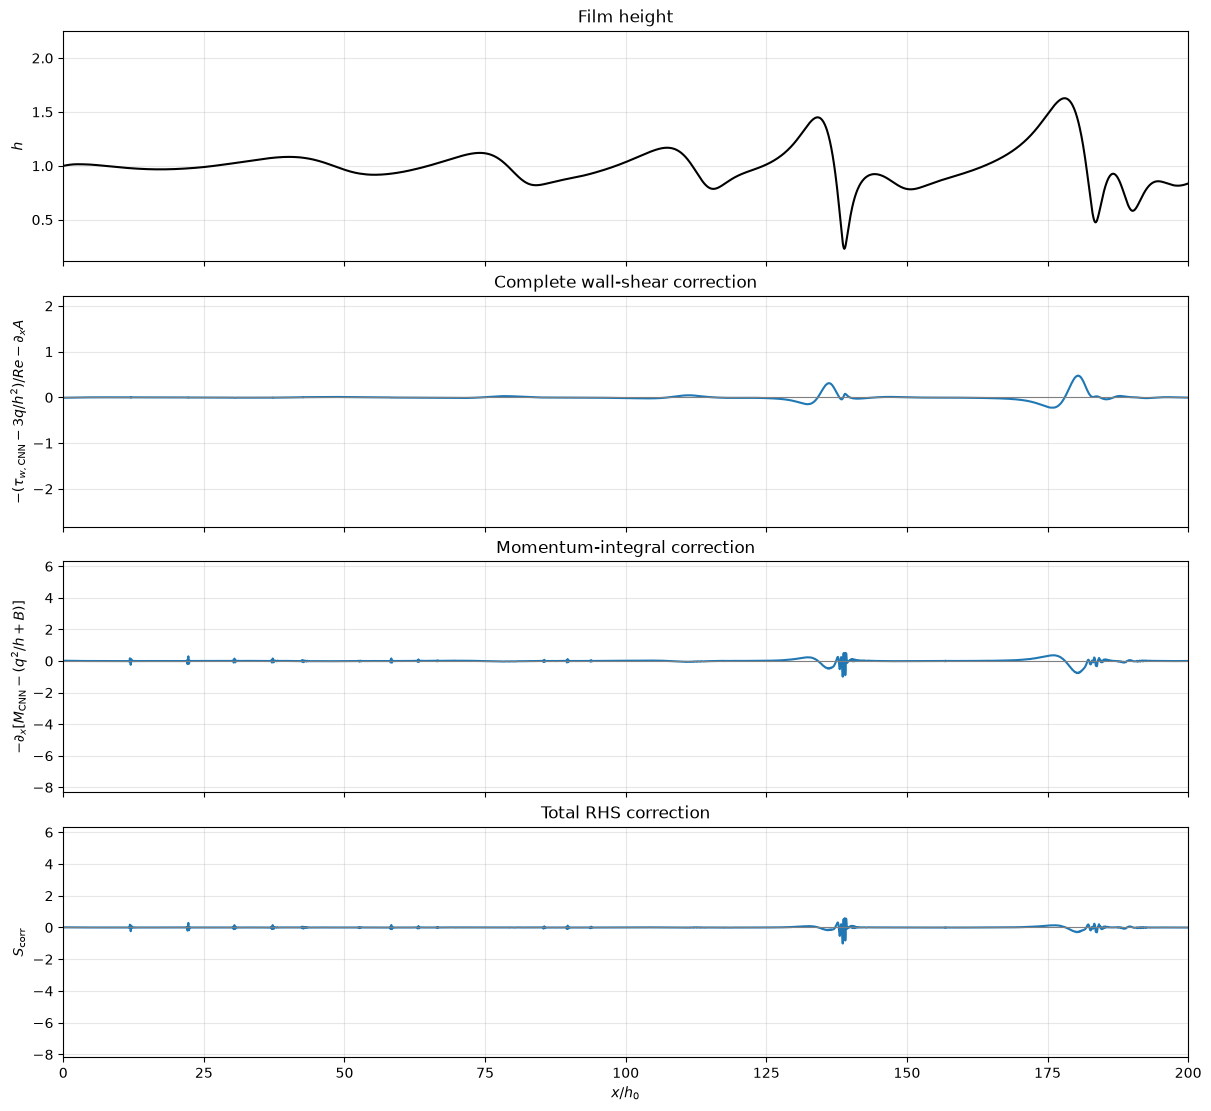

In [16]:
xlim1 = 0
xlim2 = 200
Lambda = 3.0

x1 = np.asarray(x, dtype=float)
h1 = h[:, 0]
q1 = q[:, 0]
Re = float(Re_case)

tau_cnn = results["CNN"]["full"][:, 0, 0]
M_cnn = results["CNN"]["full"][:, 0, 1]  # Predicted ∫ u² f dy

# Use the first 90% of the domain and complete CNN predictions.
x_cutoff = x1.min() + 0.9 * (x1.max() - x1.min())
valid = np.flatnonzero(
    (x1 <= x_cutoff)
    & (h1 > 0)
    & np.isfinite(h1)
    & np.isfinite(q1)
    & np.isfinite(tau_cnn)
    & np.isfinite(M_cnn)
)

if len(valid) < 3 or np.any(np.diff(valid) != 1):
    raise ValueError("Need at least three contiguous valid x points.")

xv = x1[valid]
hv = h1[valid]
qv = q1[valid]

# B is the leading-order momentum-integral contribution.
# A is the wall-shear-gradient contribution moved into Lavalle's LHS flux.
B = (Lambda**2 / 45.0) * hv**5
A = (Lambda**2 / 75.0) * hv**5

# Complete wall-shear replacement, including compensation for moved A.
rhs_shear_direct = -(tau_cnn[valid] - 3.0 * qv / hv**2) / Re
rhs_moved_term = -np.gradient(A, xv, edge_order=2)
rhs_wall = rhs_shear_direct + rhs_moved_term

# Replace Lavalle's leading-order momentum integral with the CNN integral.
delta_shape_flux = M_cnn[valid] - (qv**2 / hv + B)
rhs_shape = -np.gradient(delta_shape_flux, xv, edge_order=2)

rhs_correction = rhs_wall + rhs_shape

# Full-length arrays aligned with x; excluded locations remain NaN.
rhs_wall_full = np.full(x1.shape, np.nan)
rhs_shape_full = np.full(x1.shape, np.nan)
rhs_correction_full = np.full(x1.shape, np.nan)

rhs_wall_full[valid] = rhs_wall
rhs_shape_full[valid] = rhs_shape
rhs_correction_full[valid] = rhs_correction

fig, axes = plt.subplots(
    4, 1, figsize=(12, 11), sharex=True, constrained_layout=True
)

axes[0].plot(xv, hv, color="black")
axes[0].set_ylabel(r"$h$")
axes[0].set_title("Film height")

contributions = [
    (
        rhs_wall,
        r"$-(\tau_{w,\rm CNN}-3q/h^2)/Re-\partial_x A$",
        "Complete wall-shear correction",
    ),
    (
        rhs_shape,
        r"$-\partial_x[M_{\rm CNN}-(q^2/h+B)]$",
        "Momentum-integral correction",
    ),
    (
        rhs_correction,
        r"$S_{\rm corr}$",
        "Total RHS correction",
    ),
]

for ax, (values, ylabel, title) in zip(axes[1:], contributions):
    ax.plot(xv, values)
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.set_ylabel(ylabel)
    ax.set_title(title)

for ax in axes:
    ax.set_xlim(xlim1, xlim2)
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel(r"$x/h_0$")
plt.show()

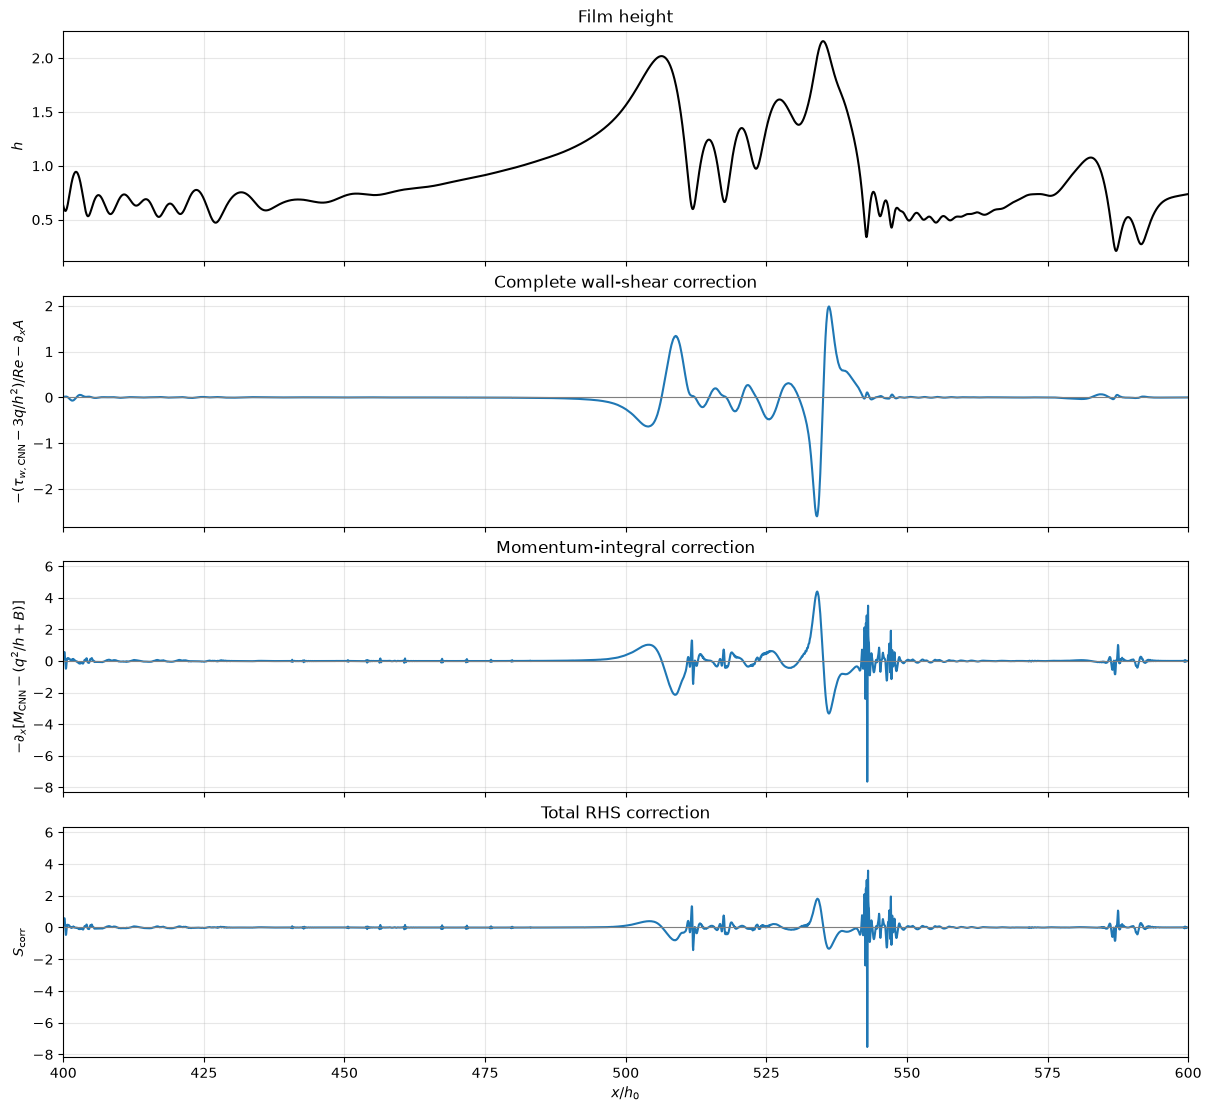

In [17]:
xlim1 = 400
xlim2 = 600
Lambda = 3.0

x1 = np.asarray(x, dtype=float)
h1 = h[:, 0]
q1 = q[:, 0]
Re = float(Re_case)

tau_cnn = results["CNN"]["full"][:, 0, 0]
M_cnn = results["CNN"]["full"][:, 0, 1]  # Predicted ∫ u² f dy

# Use the first 90% of the domain and complete CNN predictions.
x_cutoff = x1.min() + 0.9 * (x1.max() - x1.min())
valid = np.flatnonzero(
    (x1 <= x_cutoff)
    & (h1 > 0)
    & np.isfinite(h1)
    & np.isfinite(q1)
    & np.isfinite(tau_cnn)
    & np.isfinite(M_cnn)
)

if len(valid) < 3 or np.any(np.diff(valid) != 1):
    raise ValueError("Need at least three contiguous valid x points.")

xv = x1[valid]
hv = h1[valid]
qv = q1[valid]

# B is the leading-order momentum-integral contribution.
# A is the wall-shear-gradient contribution moved into Lavalle's LHS flux.
B = (Lambda**2 / 45.0) * hv**5
A = (Lambda**2 / 75.0) * hv**5

# Complete wall-shear replacement, including compensation for moved A.
rhs_shear_direct = -(tau_cnn[valid] - 3.0 * qv / hv**2) / Re
rhs_moved_term = -np.gradient(A, xv, edge_order=2)
rhs_wall = rhs_shear_direct + rhs_moved_term

# Replace Lavalle's leading-order momentum integral with the CNN integral.
delta_shape_flux = M_cnn[valid] - (qv**2 / hv + B)
rhs_shape = -np.gradient(delta_shape_flux, xv, edge_order=2)

rhs_correction = rhs_wall + rhs_shape

# Full-length arrays aligned with x; excluded locations remain NaN.
rhs_wall_full = np.full(x1.shape, np.nan)
rhs_shape_full = np.full(x1.shape, np.nan)
rhs_correction_full = np.full(x1.shape, np.nan)

rhs_wall_full[valid] = rhs_wall
rhs_shape_full[valid] = rhs_shape
rhs_correction_full[valid] = rhs_correction

fig, axes = plt.subplots(
    4, 1, figsize=(12, 11), sharex=True, constrained_layout=True
)

axes[0].plot(xv, hv, color="black")
axes[0].set_ylabel(r"$h$")
axes[0].set_title("Film height")

contributions = [
    (
        rhs_wall,
        r"$-(\tau_{w,\rm CNN}-3q/h^2)/Re-\partial_x A$",
        "Complete wall-shear correction",
    ),
    (
        rhs_shape,
        r"$-\partial_x[M_{\rm CNN}-(q^2/h+B)]$",
        "Momentum-integral correction",
    ),
    (
        rhs_correction,
        r"$S_{\rm corr}$",
        "Total RHS correction",
    ),
]

for ax, (values, ylabel, title) in zip(axes[1:], contributions):
    ax.plot(xv, values)
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.set_ylabel(ylabel)
    ax.set_title(title)

for ax in axes:
    ax.set_xlim(xlim1, xlim2)
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel(r"$x/h_0$")
plt.show()

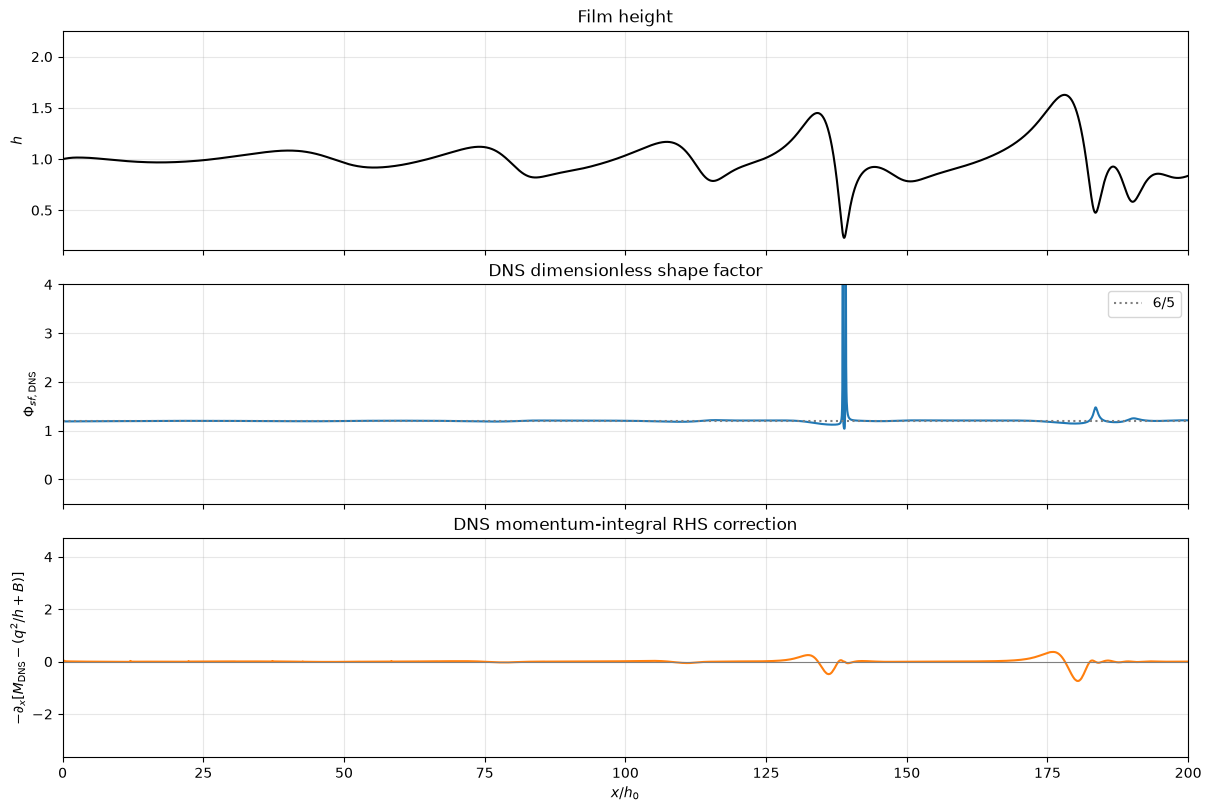

In [18]:
xlim1, xlim2 = 0, 200
Lambda = 3.0

x1 = np.asarray(x, dtype=float)
h1 = h[:, 0]
q1 = q[:, 0]
M_dns = Y_dns[:, 0, 1]  # DNS integral ∫ u² f dy

x_cutoff = x1.min() + 0.9 * (x1.max() - x1.min())
valid_shape = np.flatnonzero(
    (x1 <= x_cutoff)
    & np.isfinite(h1)
    & np.isfinite(q1)
    & np.isfinite(M_dns)
    & (h1 > 0)
    & (np.abs(q1) > 1e-12)
)

if len(valid_shape) < 3 or np.any(np.diff(valid_shape) != 1):
    raise ValueError("Need at least three contiguous valid x points.")

xs = x1[valid_shape]
hs = h1[valid_shape]
qs = q1[valid_shape]

phi_sf_dns = M_dns[valid_shape] / (qs**2 / hs)

B = (Lambda**2 / 45.0) * hs**5
rhs_shape_dns = -np.gradient(
    M_dns[valid_shape] - (qs**2 / hs + B),
    xs,
    edge_order=2,
)

fig, axes = plt.subplots(
    3, 1, figsize=(12, 8), sharex=True, constrained_layout=True
)

axes[0].plot(xs, hs, color="black")
axes[0].set_ylabel(r"$h$")
axes[0].set_title("Film height")

axes[1].plot(xs, phi_sf_dns, color="tab:blue")
axes[1].axhline(6/5, color="gray", linestyle=":", label=r"$6/5$")
axes[1].set_ylabel(r"$\Phi_{sf,\rm DNS}$")
axes[1].set_title("DNS dimensionless shape factor")
axes[1].legend()
axes[1].set_ylim(-0.5, 4)

axes[2].plot(xs, rhs_shape_dns, color="tab:orange")
axes[2].axhline(0, color="gray", linewidth=0.8)
axes[2].set_ylabel(r"$-\partial_x[M_{\rm DNS}-(q^2/h+B)]$")
axes[2].set_title("DNS momentum-integral RHS correction")
axes[2].set_xlabel(r"$x/h_0$")

for ax in axes:
    ax.set_xlim(xlim1, xlim2)
    ax.grid(True, alpha=0.3)

plt.show()

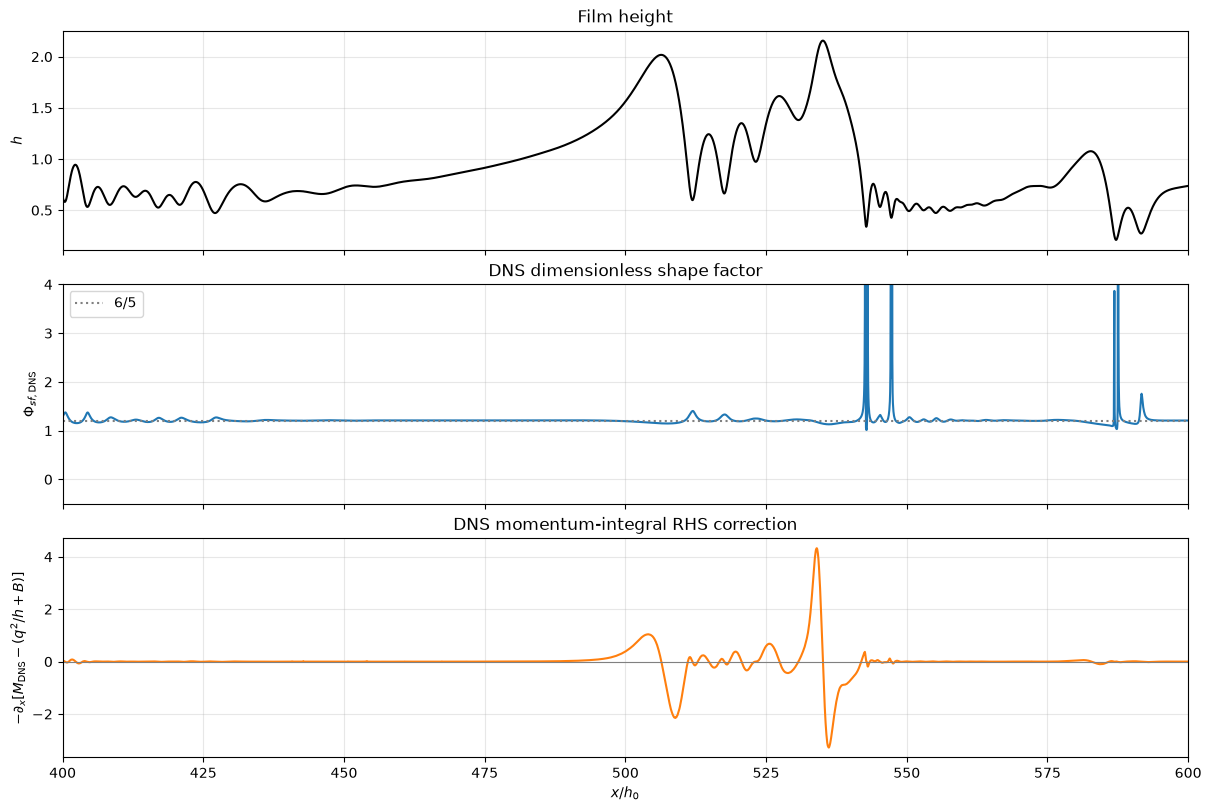

In [19]:
xlim1, xlim2 = 400, 600
Lambda = 3.0

x1 = np.asarray(x, dtype=float)
h1 = h[:, 0]
q1 = q[:, 0]
M_dns = Y_dns[:, 0, 1]  # DNS integral ∫ u² f dy

x_cutoff = x1.min() + 0.9 * (x1.max() - x1.min())
valid_shape = np.flatnonzero(
    (x1 <= x_cutoff)
    & np.isfinite(h1)
    & np.isfinite(q1)
    & np.isfinite(M_dns)
    & (h1 > 0)
    & (np.abs(q1) > 1e-12)
)

if len(valid_shape) < 3 or np.any(np.diff(valid_shape) != 1):
    raise ValueError("Need at least three contiguous valid x points.")

xs = x1[valid_shape]
hs = h1[valid_shape]
qs = q1[valid_shape]

phi_sf_dns = M_dns[valid_shape] / (qs**2 / hs)

B = (Lambda**2 / 45.0) * hs**5
rhs_shape_dns = -np.gradient(
    M_dns[valid_shape] - (qs**2 / hs + B),
    xs,
    edge_order=2,
)

fig, axes = plt.subplots(
    3, 1, figsize=(12, 8), sharex=True, constrained_layout=True
)

axes[0].plot(xs, hs, color="black")
axes[0].set_ylabel(r"$h$")
axes[0].set_title("Film height")

axes[1].plot(xs, phi_sf_dns, color="tab:blue")
axes[1].axhline(6/5, color="gray", linestyle=":", label=r"$6/5$")
axes[1].set_ylabel(r"$\Phi_{sf,\rm DNS}$")
axes[1].set_title("DNS dimensionless shape factor")
axes[1].legend()
axes[1].set_ylim(-0.5, 4)

axes[2].plot(xs, rhs_shape_dns, color="tab:orange")
axes[2].axhline(0, color="gray", linewidth=0.8)
axes[2].set_ylabel(r"$-\partial_x[M_{\rm DNS}-(q^2/h+B)]$")
axes[2].set_title("DNS momentum-integral RHS correction")
axes[2].set_xlabel(r"$x/h_0$")

for ax in axes:
    ax.set_xlim(xlim1, xlim2)
    ax.grid(True, alpha=0.3)

plt.show()

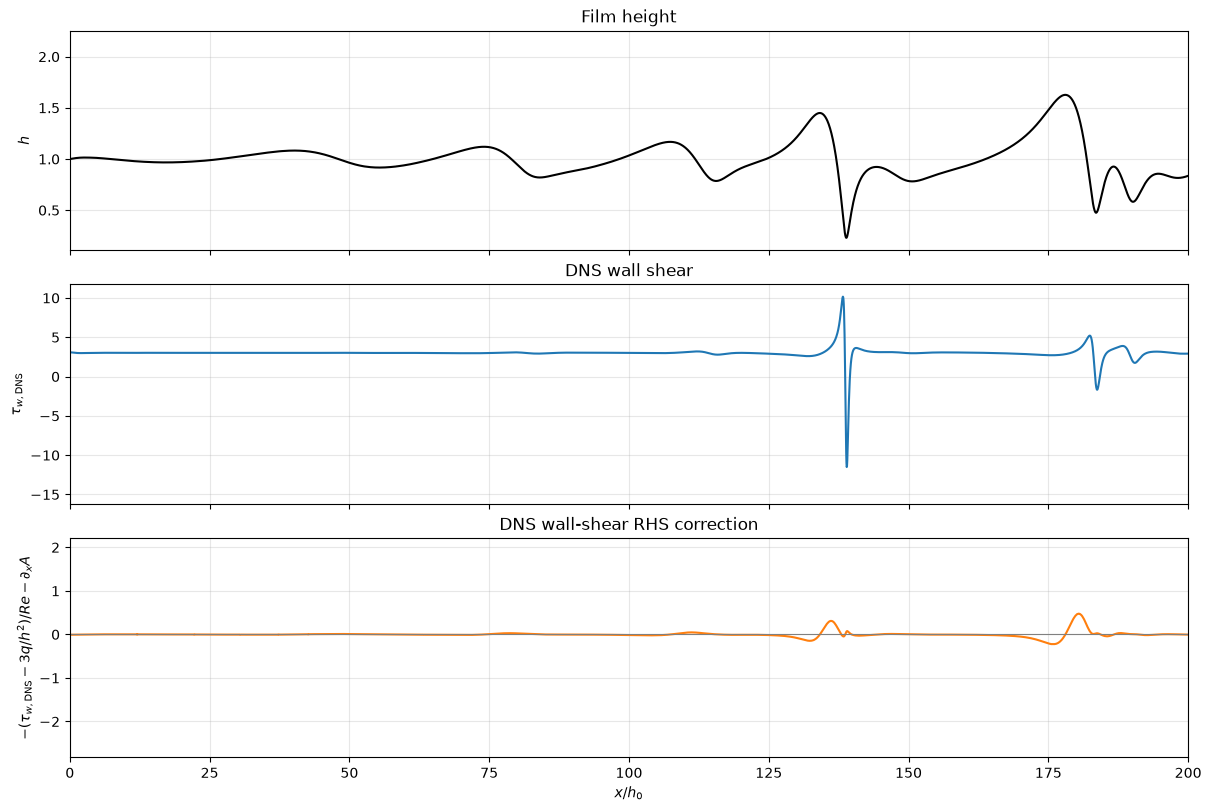

In [20]:
xlim1, xlim2 = 0, 200
Lambda = 3.0
Re = float(Re_case)

x1 = np.asarray(x, dtype=float)
h1 = h[:, 0]
q1 = q[:, 0]
tau_dns = Y_dns[:, 0, 0]

x_cutoff = x1.min() + 0.9 * (x1.max() - x1.min())
valid_wall = np.flatnonzero(
    (x1 <= x_cutoff)
    & np.isfinite(h1)
    & np.isfinite(q1)
    & np.isfinite(tau_dns)
    & (h1 > 0)
)

if len(valid_wall) < 3 or np.any(np.diff(valid_wall) != 1):
    raise ValueError("Need at least three contiguous valid x points.")

xw = x1[valid_wall]
hw = h1[valid_wall]
qw = q1[valid_wall]
tauw = tau_dns[valid_wall]

# Compensation for the wall-shear h_x term retained in Lavalle's LHS flux.
A = (Lambda**2 / 75.0) * hw**5

rhs_wall_dns = (
    -(tauw - 3.0 * qw / hw**2) / Re
    - np.gradient(A, xw, edge_order=2)
)

fig, axes = plt.subplots(
    3, 1, figsize=(12, 8), sharex=True, constrained_layout=True
)

axes[0].plot(xw, hw, color="black")
axes[0].set_ylabel(r"$h$")
axes[0].set_title("Film height")

axes[1].plot(xw, tauw, color="tab:blue")
axes[1].set_ylabel(r"$\tau_{w,\rm DNS}$")
axes[1].set_title("DNS wall shear")

axes[2].plot(xw, rhs_wall_dns, color="tab:orange")
axes[2].axhline(0, color="gray", linewidth=0.8)
axes[2].set_ylabel(r"$-(\tau_{w,\rm DNS}-3q/h^2)/Re-\partial_x A$")
axes[2].set_title("DNS wall-shear RHS correction")
axes[2].set_xlabel(r"$x/h_0$")

for ax in axes:
    ax.set_xlim(xlim1, xlim2)
    ax.grid(True, alpha=0.3)

plt.show()

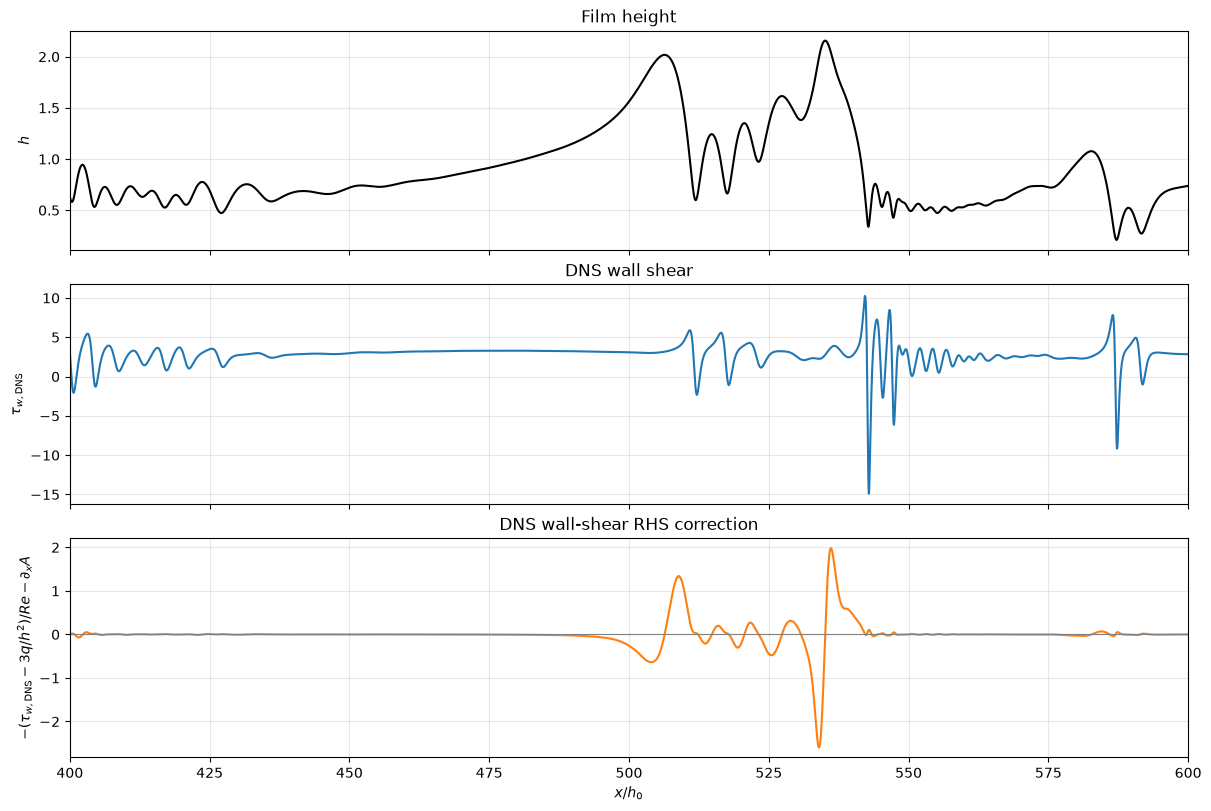

In [21]:
xlim1, xlim2 = 400, 600
Lambda = 3.0
Re = float(Re_case)

x1 = np.asarray(x, dtype=float)
h1 = h[:, 0]
q1 = q[:, 0]
tau_dns = Y_dns[:, 0, 0]

x_cutoff = x1.min() + 0.9 * (x1.max() - x1.min())
valid_wall = np.flatnonzero(
    (x1 <= x_cutoff)
    & np.isfinite(h1)
    & np.isfinite(q1)
    & np.isfinite(tau_dns)
    & (h1 > 0)
)

if len(valid_wall) < 3 or np.any(np.diff(valid_wall) != 1):
    raise ValueError("Need at least three contiguous valid x points.")

xw = x1[valid_wall]
hw = h1[valid_wall]
qw = q1[valid_wall]
tauw = tau_dns[valid_wall]

# Compensation for the wall-shear h_x term retained in Lavalle's LHS flux.
A = (Lambda**2 / 75.0) * hw**5

rhs_wall_dns = (
    -(tauw - 3.0 * qw / hw**2) / Re
    - np.gradient(A, xw, edge_order=2)
)

fig, axes = plt.subplots(
    3, 1, figsize=(12, 8), sharex=True, constrained_layout=True
)

axes[0].plot(xw, hw, color="black")
axes[0].set_ylabel(r"$h$")
axes[0].set_title("Film height")

axes[1].plot(xw, tauw, color="tab:blue")
axes[1].set_ylabel(r"$\tau_{w,\rm DNS}$")
axes[1].set_title("DNS wall shear")

axes[2].plot(xw, rhs_wall_dns, color="tab:orange")
axes[2].axhline(0, color="gray", linewidth=0.8)
axes[2].set_ylabel(r"$-(\tau_{w,\rm DNS}-3q/h^2)/Re-\partial_x A$")
axes[2].set_title("DNS wall-shear RHS correction")
axes[2].set_xlabel(r"$x/h_0$")

for ax in axes:
    ax.set_xlim(xlim1, xlim2)
    ax.grid(True, alpha=0.3)

plt.show()

Now, plotting comparison of DNS vs CNN corrections in the linear and non-linear regimes

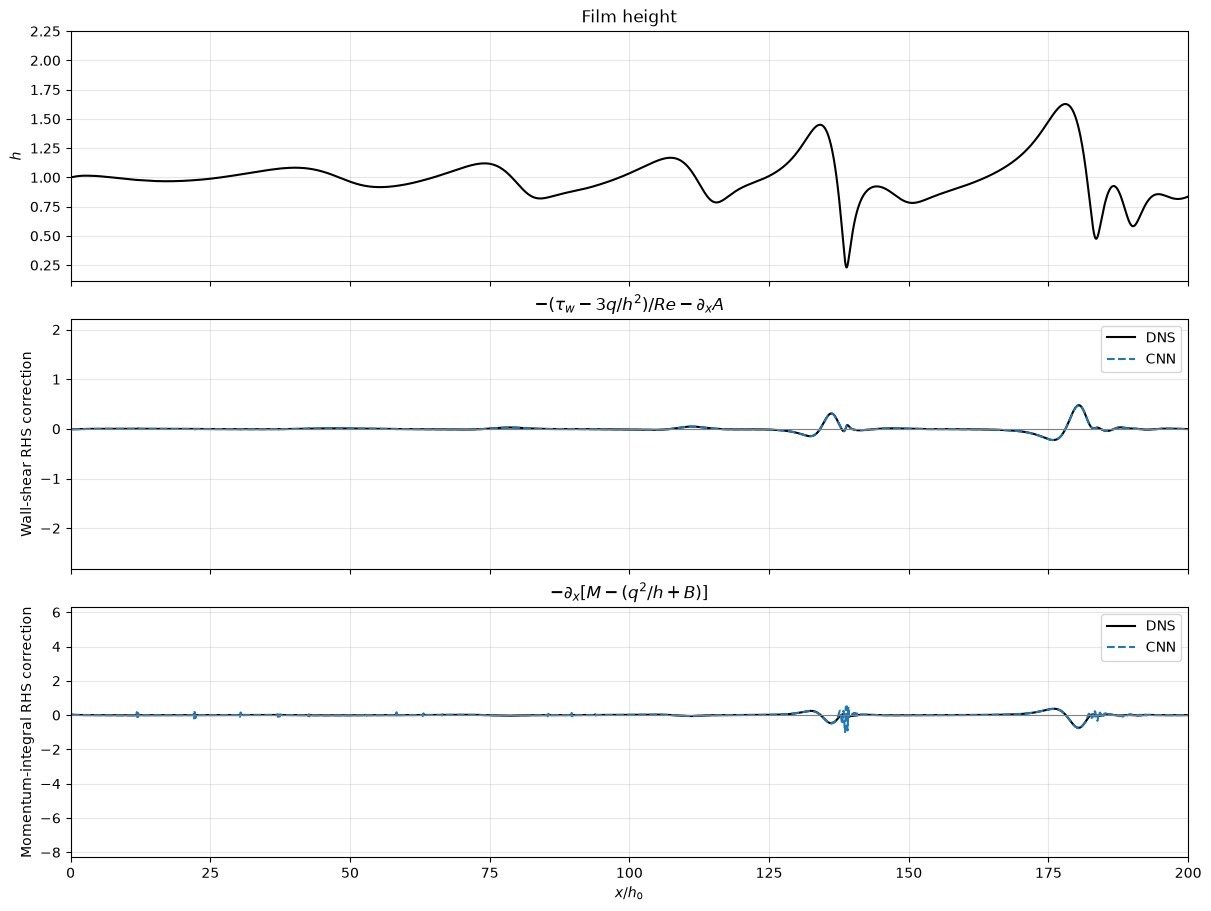

In [22]:
xlim1, xlim2 = 0, 200
Lambda = 3.0
Re = float(Re_case)

x1 = np.asarray(x, dtype=float)
h1 = h[:, 0]
q1 = q[:, 0]

tau_dns = Y_dns[:, 0, 0]
M_dns = Y_dns[:, 0, 1]

tau_cnn = results["CNN"]["full"][:, 0, 0]
M_cnn = results["CNN"]["full"][:, 0, 1]

# Use the first 90% of the domain and locations with both CNN predictions.
x_cutoff = x1.min() + 0.9 * (x1.max() - x1.min())
valid = np.flatnonzero(
    (x1 <= x_cutoff)
    & np.isfinite(h1)
    & np.isfinite(q1)
    & np.isfinite(tau_dns)
    & np.isfinite(M_dns)
    & np.isfinite(tau_cnn)
    & np.isfinite(M_cnn)
    & (h1 > 0)
)

if len(valid) < 3 or np.any(np.diff(valid) != 1):
    raise ValueError("Need at least three contiguous valid x points.")

xv = x1[valid]
hv = h1[valid]
qv = q1[valid]

# A compensates for the wall-shear h_x term moved to Lavalle's LHS flux.
# B is the leading-order momentum-integral contribution.
A = (Lambda**2 / 75.0) * hv**5
B = (Lambda**2 / 45.0) * hv**5

moved_term = -np.gradient(A, xv, edge_order=2)

rhs_wall_dns = (
    -(tau_dns[valid] - 3.0 * qv / hv**2) / Re
    + moved_term
)
rhs_wall_cnn = (
    -(tau_cnn[valid] - 3.0 * qv / hv**2) / Re
    + moved_term
)

baseline_integral = qv**2 / hv + B

rhs_integral_dns = -np.gradient(
    M_dns[valid] - baseline_integral, xv, edge_order=2
)
rhs_integral_cnn = -np.gradient(
    M_cnn[valid] - baseline_integral, xv, edge_order=2
)

fig, axes = plt.subplots(
    3, 1, figsize=(12, 9), sharex=True, constrained_layout=True
)

axes[0].plot(xv, hv, color="black")
axes[0].set_ylabel(r"$h$")
axes[0].set_title("Film height")

axes[1].plot(xv, rhs_wall_dns, color="black", label="DNS")
axes[1].plot(xv, rhs_wall_cnn, "--", color="tab:blue", label="CNN")
axes[1].axhline(0, color="gray", linewidth=0.8)
axes[1].set_ylabel("Wall-shear RHS correction")
axes[1].set_title(r"$-(\tau_w-3q/h^2)/Re-\partial_x A$")
axes[1].legend()

axes[2].plot(xv, rhs_integral_dns, color="black", label="DNS")
axes[2].plot(xv, rhs_integral_cnn, "--", color="tab:blue", label="CNN")
axes[2].axhline(0, color="gray", linewidth=0.8)
axes[2].set_ylabel("Momentum-integral RHS correction")
axes[2].set_title(r"$-\partial_x[M-(q^2/h+B)]$")
axes[2].set_xlabel(r"$x/h_0$")
axes[2].legend()

for ax in axes:
    ax.set_xlim(xlim1, xlim2)
    ax.grid(True, alpha=0.3)

plt.show()

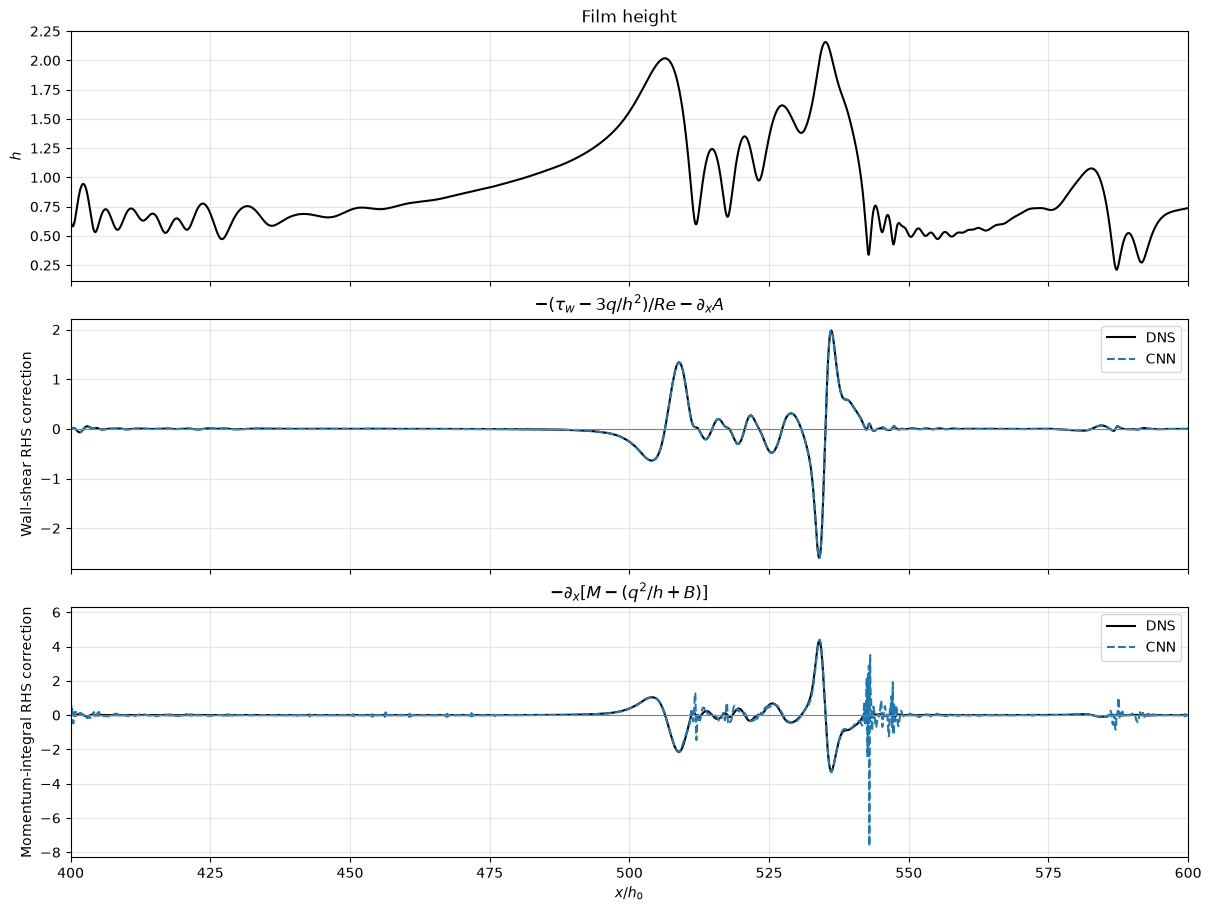

In [23]:
xlim1, xlim2 = 400, 600
Lambda = 3.0
Re = float(Re_case)

x1 = np.asarray(x, dtype=float)
h1 = h[:, 0]
q1 = q[:, 0]

tau_dns = Y_dns[:, 0, 0]
M_dns = Y_dns[:, 0, 1]

tau_cnn = results["CNN"]["full"][:, 0, 0]
M_cnn = results["CNN"]["full"][:, 0, 1]

# Use the first 90% of the domain and locations with both CNN predictions.
x_cutoff = x1.min() + 0.9 * (x1.max() - x1.min())
valid = np.flatnonzero(
    (x1 <= x_cutoff)
    & np.isfinite(h1)
    & np.isfinite(q1)
    & np.isfinite(tau_dns)
    & np.isfinite(M_dns)
    & np.isfinite(tau_cnn)
    & np.isfinite(M_cnn)
    & (h1 > 0)
)

if len(valid) < 3 or np.any(np.diff(valid) != 1):
    raise ValueError("Need at least three contiguous valid x points.")

xv = x1[valid]
hv = h1[valid]
qv = q1[valid]

# A compensates for the wall-shear h_x term moved to Lavalle's LHS flux.
# B is the leading-order momentum-integral contribution.
A = (Lambda**2 / 75.0) * hv**5
B = (Lambda**2 / 45.0) * hv**5

moved_term = -np.gradient(A, xv, edge_order=2)

rhs_wall_dns = (
    -(tau_dns[valid] - 3.0 * qv / hv**2) / Re
    + moved_term
)
rhs_wall_cnn = (
    -(tau_cnn[valid] - 3.0 * qv / hv**2) / Re
    + moved_term
)

baseline_integral = qv**2 / hv + B

rhs_integral_dns = -np.gradient(
    M_dns[valid] - baseline_integral, xv, edge_order=2
)
rhs_integral_cnn = -np.gradient(
    M_cnn[valid] - baseline_integral, xv, edge_order=2
)

fig, axes = plt.subplots(
    3, 1, figsize=(12, 9), sharex=True, constrained_layout=True
)

axes[0].plot(xv, hv, color="black")
axes[0].set_ylabel(r"$h$")
axes[0].set_title("Film height")

axes[1].plot(xv, rhs_wall_dns, color="black", label="DNS")
axes[1].plot(xv, rhs_wall_cnn, "--", color="tab:blue", label="CNN")
axes[1].axhline(0, color="gray", linewidth=0.8)
axes[1].set_ylabel("Wall-shear RHS correction")
axes[1].set_title(r"$-(\tau_w-3q/h^2)/Re-\partial_x A$")
axes[1].legend()

axes[2].plot(xv, rhs_integral_dns, color="black", label="DNS")
axes[2].plot(xv, rhs_integral_cnn, "--", color="tab:blue", label="CNN")
axes[2].axhline(0, color="gray", linewidth=0.8)
axes[2].set_ylabel("Momentum-integral RHS correction")
axes[2].set_title(r"$-\partial_x[M-(q^2/h+B)]$")
axes[2].set_xlabel(r"$x/h_0$")
axes[2].legend()

for ax in axes:
    ax.set_xlim(xlim1, xlim2)
    ax.grid(True, alpha=0.3)

plt.show()

In [24]:
solver_dir = Path(
    "/blue/bala1s/krishnap.kalivel/TLFHydrodynamics/"
    "thinfilm-closure-ml/codes/rom-solver/thinfilm-nekrs/ml-integrated-cpp"
)
file_path = solver_dir / "thinfilm_training_data.h5"

with h5py.File(file_path, "r") as f:
    x = f["x"][:]
    time = f["time"][:]

    # Arrays have shape (number of saved times, number of x locations).
    h = f["h"][:]
    q = f["q"][:]

    lavalle_wall_friction = f["terms/lavalle_wall_friction"][:]
    lavalle_pressure_flux = f["terms/lavalle_pressure_flux_gradient"][:]
    wall_correction = f["terms/wall_correction"][:]
    momentum_integral_correction = f["terms/momentum_integral_correction"][:]

    parameters = dict(f.attrs)

total_correction = wall_correction + momentum_integral_correction

print("File:", file_path)
print("x:", x.shape, "time:", time.shape, "h:", h.shape)

File: /blue/bala1s/krishnap.kalivel/TLFHydrodynamics/thinfilm-closure-ml/codes/rom-solver/thinfilm-nekrs/ml-integrated-cpp/thinfilm_training_data.h5
x: (16384,) time: (20,) h: (20, 16384)


In [25]:
with h5py.File(file_path, "r") as f:
    def show_dataset(name, obj):
        if isinstance(obj, h5py.Dataset):
            print(f"{name}: shape={obj.shape}, dtype={obj.dtype}")

    f.visititems(show_dataset)

forcing/F_inlet: shape=(20,), dtype=float64
forcing/q_inlet: shape=(20,), dtype=float64
h: shape=(20, 16384), dtype=float64
h_t: shape=(20, 16384), dtype=float64
h_x: shape=(20, 16384), dtype=float64
h_xx: shape=(20, 16384), dtype=float64
h_xxx: shape=(20, 16384), dtype=float64
q: shape=(20, 16384), dtype=float64
q_t: shape=(20, 16384), dtype=float64
q_x: shape=(20, 16384), dtype=float64
q_xx: shape=(20, 16384), dtype=float64
qh: shape=(20, 16384), dtype=float64
qh_x: shape=(20, 16384), dtype=float64
qh_xx: shape=(20, 16384), dtype=float64
r: shape=(20, 16384), dtype=float64
terms/lavalle_pressure_flux_gradient: shape=(20, 16384), dtype=float64
terms/lavalle_wall_friction: shape=(20, 16384), dtype=float64
terms/momentum_integral_correction: shape=(20, 16384), dtype=float64
terms/wall_correction: shape=(20, 16384), dtype=float64
time: shape=(20,), dtype=float64
x: shape=(16384,), dtype=float64


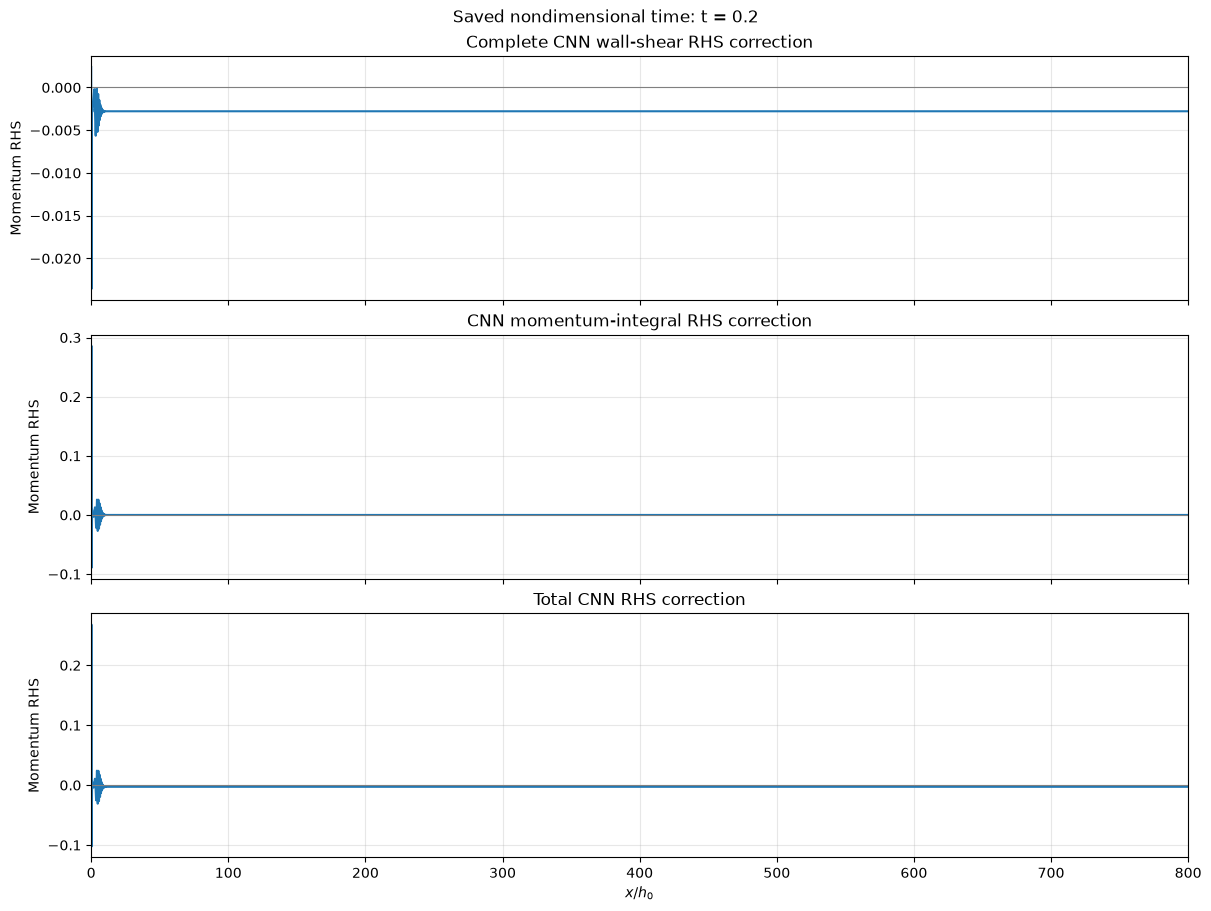

In [26]:
it = -1  # Last saved snapshot
xlim1, xlim2 = 0, 

with h5py.File(file_path, "r") as f:
    x = f["x"][:]
    t_plot = f["time"][it]
    wall = f["terms/wall_correction"][it, :]
    integral = f["terms/momentum_integral_correction"][it, :]

fig, axes = plt.subplots(
    3, 1, figsize=(12, 9), sharex=True, constrained_layout=True
)

for ax, values, title in zip(
    axes,
    [wall, integral, wall + integral],
    [
        "Complete CNN wall-shear RHS correction",
        "CNN momentum-integral RHS correction",
        "Total CNN RHS correction",
    ],
):
    ax.plot(x, values)
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.set_title(title)
    ax.set_ylabel("Momentum RHS")
    ax.set_xlim(xlim1, xlim2)
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel(r"$x/h_0$")
fig.suptitle(f"Saved nondimensional time: t = {t_plot:.6g}")
plt.show()